# PBL 과제 ① 기본 LSTM 차량 궤적 예측

5조 · 정채환 · 전재현 · 진하영 · 최형빈

제공된 전처리 US-101 데이터 10,000개 시나리오를 모두 활용한다. LSTM 유닛 64/128 × 과거 관측 1/2초 × 미래 예측 3/5초의 8개 조건을 비교한다.

**읽는 순서:** 실행 준비 → 데이터 구조·품질 → EDA → 모델 입력·분할 → 필수 8개 실험·평가 → 추가 오차 분석 → 기준 모델·중첩 점검 → 결론

**실행 안내:** 기본값은 저장 결과 재사용이다. `RUN_TRAINING = False`를 유지하면 다시 학습하지 않는다. 추가 분석은 저장 모델로 추론하므로 실행 시간이 필요하다. 원본 `raw_data`는 변경하지 않는다.

표·그림 출력은 정리 전 최신 노트북의 저장 결과를 보존했다. 셀을 재배치한 뒤 현재 컴퓨터에서 Colab 모델을 다시 실행한 결과는 아니다. 실행 번호는 초기화했다.

**해석 범위:** 기본 표는 부재 차량 채움값을 포함한 전체 7대의 정규화 좌표 성분 오차다. 추가 분석은 Ego의 원래 좌표 성분 오차다. 학습·평가 사이 동일 차량·프레임 중첩이 확인되어 독립 장면 일반화 성능을 주장하지 않는다.


## 연구 질문과 예상

다음 연구 질문과 예상은 완료된 분석의 목적과 결과를 설명하기 위해 결과 확인 후 정리하였다. 분석 전에 등록한 가설이나 독립 자료를 이용한 가설검정 결과가 아니며, 예상과 관찰 결과를 구분한다.

| 구분 | 연구 질문 | 예상 |
|---|---|---|
| RQ1 유닛 수 | 같은 관측·예측 길이에서 LSTM 유닛을 64개에서 128개로 늘리면 오차가 줄어드는가? | 표현 용량 증가가 오차 감소에 도움이 될 수 있다. |
| RQ2 과거 관측 길이 | 과거 관측을 1초에서 2초로 늘리면 오차가 줄어드는가? | 추가 과거 정보가 미래 움직임을 파악하는 데 도움이 될 수 있다. |
| RQ3 미래 예측 길이 | 미래 예측 구간이 3초에서 5초로 길어지면 오차가 커지는가? | 먼 미래의 불확실성 때문에 원래 좌표 오차가 커질 수 있다. |
| RQ4 차로 상태 | 전체 7초 동안 차로 ID가 변화한 집단은 유지 집단보다 오차가 큰가? | 상황 차이에 따라 예측 난도와 오차가 다를 수 있다. |
| RQ5 기준 모델 | 검증으로 선택한 LSTM은 최근 1초 변위로 속도를 추정한 일정속도 모델보다 정확한가? | 학습한 움직임의 패턴이 일정속도 가정보다 유리할 수 있다. |

결과는 26단계 결론에서 질문별로 정리한다. 정규화 전체 7대 지표와 원래 좌표 Ego 지표를 구분하며, 사전 가설검정·통계적 유의성·인과 효과로 표현하지 않는다.


## 01 Google Drive 연결

Colab 커널에서 실행한다. GPU 정보는 모델 구성 단계에서 확인한다.

In [ ]:
# Colab 실행 환경에서 Google Drive에 접근하기 위한 모듈
from google.colab import drive

# 실행 후 안내에 따라 Google 계정 연결을 승인
drive.mount("/content/drive")

## 02 파일 경로와 실행 모드

기존 결과를 재사용한다. 새로운 학습을 의도한 경우에만 실행 모드를 변경한다.

파일과 결과 폴더를 확인하고 실행 모드를 결정한다.

기본값 RUN_TRAINING=False는 기존 학습 결과를 재사용한다. 저장 모델과 scaler·분할은 반드시 같은 실험 폴더의 파일을 사용한다.


In [ ]:
import os
from pathlib import Path

# 실제 Google Drive 폴더 위치와 파일명 지정
data_path = Path(
    "/content/drive/MyDrive/교통물류데이터과학인공지능/"
    "US101_0750_0805_scene(sample).pickle"
)

# 해당 위치에 파일이 있는지 확인
if not data_path.is_file():
    raise FileNotFoundError(f"파일을 찾지 못했습니다:\n{data_path}")

print("파일명:", data_path.name)
print(f"파일 크기: {data_path.stat().st_size / (1024 ** 2):,.1f} MB")

### 02.1 저장 결과 재사용 설정

기존 실험 폴더를 지정한다. 기본값을 유지하면 학습을 반복하지 않는다.


In [ ]:
# 기본 실행은 저장된 실험 결과 재사용
RUN_TRAINING = False
SAVED_BATCH_DIR = Path(os.environ.get("LSTM_RESULTS_DIR", str(data_path.parent / "PBL1_results" / "course_required_20261109_062604_119669")))
batch_dir = SAVED_BATCH_DIR
if not RUN_TRAINING and not (batch_dir / 'manifest.json').is_file():
    raise FileNotFoundError(f'저장 실험 경로를 확인하세요: {batch_dir}')
print('실행 모드:', '새로운 8개 모델 학습' if RUN_TRAINING else '기존 모델·결과 재사용')


## 03 데이터 로딩과 배열 구조

Pickle은 저장 형식이다. 내부 데이터는 (시나리오, 차량 슬롯, 시점, 특성) 순서의 수치 배열이다. 신뢰할 수 있는 교수님 제공 파일만 연다.

In [ ]:
import pickle
import numpy as np

# 교수님 제공 파일만 불러오기: 신뢰할 수 있는 Pickle만 사용
# raw_data는 원본으로 유지하고, 모델 입력 변환은 별도 배열에서 수행
with data_path.open("rb") as file:
    raw_data = pickle.load(file)

# 데이터 자료형 확인
print("데이터 자료형:", type(raw_data))

if isinstance(raw_data, np.ndarray):
    # 배열 크기, 값의 자료형, 메모리 사용량 확인
    print("배열 크기:", raw_data.shape)
    print("값의 자료형:", raw_data.dtype)
    print(f"배열 메모리: {raw_data.nbytes / (1024 ** 2):,.1f} MB")

    # 시나리오 × 차량 × 시점 × 특성
    if raw_data.ndim == 4:
        print("\n[데이터 구성]")
        print(f"시나리오: {raw_data.shape[0]:,}개")
        print(f"차량: {raw_data.shape[1]}대")
        print(f"시점: {raw_data.shape[2]}개")
        print(f"특성: {raw_data.shape[3]}개")

elif isinstance(raw_data, dict):
    # 내부에 저장된 데이터 이름 확인
    print("저장된 키:", list(raw_data.keys())[:20])

elif isinstance(raw_data, (list, tuple)):
    # 항목 수와 첫 항목의 구조 확인
    print("항목 수:", len(raw_data))

    if len(raw_data) > 0:
        print("첫 항목 자료형:", type(raw_data[0]))
        print("첫 항목 크기:", np.shape(raw_data[0]))

## 04 특성 정의와 표 확인



In [ ]:
import pandas as pd

# 강의자료에 제시된 14개 특성 이름을 배열 순서대로 지정
feature_names = [
    "Vehicle_ID", "Frame_ID", "x", "y",
    "length", "width", "class", "speed",
    "acceleration", "Lane_ID", "Front_id", "Rear_id",
    "Headway", "Time_headway"
]

# 첫 번째 시나리오의 첫 번째 차량을 선택
# 실습 코드에서 슬롯 0은 상대좌표 기준 Ego 차량
scenario_idx = 0
vehicle_idx = 0

# 해당 차량의 71개 시점을 71행 × 14열 표로 변환
# 원본 raw_data는 변경하지 않음
sample_df = pd.DataFrame(
    raw_data[scenario_idx, vehicle_idx, :, :],
    columns=feature_names
)
sample_df.index.name = "Time_step"

# 표 크기와 처음 10개 시점 확인
print("표 크기:", sample_df.shape)

# 모든 컬럼이 표시되도록 설정
with pd.option_context("display.max_columns", None):
    display(sample_df.head(10))

## 05 결측과 프레임 기본 점검

원본을 삭제·대체하지 않고 상태를 확인한다. 첫 시나리오의 점검을 전체 시나리오 연속성 검증으로 확대 해석하지 않는다.

결측과 무한대, 첫 시나리오의 차량 ID·프레임 구성을 확인한다.

주변 차량 부재의 NaN과 실제 수집 오류를 구분한다. 원본을 임의 삭제·보간하지 않으며, 첫 사례 확인을 전체 연속성 검증으로 확대하지 않는다.


In [ ]:
# 특성별 NaN과 무한대 개수 확인
# 값의 삭제·대체 없이 상태만 점검
check_rows = []

for idx, name in enumerate(feature_names):
    values = raw_data[..., idx]

    check_rows.append({
        "특성": name,
        "NaN 수": int(np.isnan(values).sum()),
        "무한대 수": int(np.isinf(values).sum())
    })

display(pd.DataFrame(check_rows))

# 첫 번째 시나리오에서 차량 슬롯별 ID와 프레임 구성 확인
# 슬롯은 배열 안의 차량 위치이며, 실제 차량 ID와 다름
slot_rows = []

for slot in range(raw_data.shape[1]):
    vehicle_ids = raw_data[0, slot, :, 0]
    frames = raw_data[0, slot, :, 1]

    slot_rows.append({
        "차량 슬롯": slot,
        "차량 ID 종류": np.unique(vehicle_ids).tolist(),
        "시작 프레임": frames[0],
        "종료 프레임": frames[-1],
        "프레임 차이 종류": np.unique(np.diff(frames)).tolist()
    })

display(pd.DataFrame(slot_rows))

# 시간 간격이 0.1초이면, 71개 관측점의 처음~끝 간격은 7초
print("시점 수:", raw_data.shape[2])
print("0.1초 간격 가정 시 처음~끝 길이:",
      round((raw_data.shape[2] - 1) * 0.1, 1), "초")

## 06 시나리오별 주행 특성 요약

같은 차량이 반복 포함될 수 있으므로 분석 단위는 시나리오다.

In [ ]:
# 원본 배열에서 Ego 차량(슬롯 0)의 정보만 참조
# raw_data는 변경하지 않음
ego_data = raw_data[:, 0, :, :]

# 강의자료의 특성 순서 기준
ego_ids = ego_data[:, 0, 0]
speed = ego_data[:, :, 7]
acceleration = ego_data[:, :, 8]
lane = ego_data[:, :, 9]

# 차로 ID가 유효하고 양수인 경우에만 차로 변화 판단
valid_lane = (
    np.isfinite(lane).all(axis=1)
    & (lane > 0).all(axis=1)
)

# 71개 시점 안에서 차로 ID 변화 여부 확인
lane_changed = np.any(np.diff(lane, axis=1) != 0, axis=1)

# 차로 변화가 있다고 해서 정상적인 차로 변경이 확정되는 것은 아님
lane_status = np.full(len(ego_data), "Unknown", dtype=object)
lane_status[valid_lane & ~lane_changed] = "Lane ID maintained"
lane_status[valid_lane & lane_changed] = "Lane ID changed"

# 시나리오마다 하나의 요약 행 생성
scenario_eda = pd.DataFrame({
    "scenario_idx": np.arange(len(ego_data)),
    "ego_vehicle_id": ego_ids,
    "initial_speed": speed[:, 0],
    "mean_speed": np.nanmean(speed, axis=1),
    "mean_acceleration": np.nanmean(acceleration, axis=1),
    "lane_status": lane_status
})

# 기본 규모 확인
summary = pd.DataFrame({
    "항목": [
        "전체 시나리오 수",
        "고유 Ego 차량 수",
        "시나리오당 차량 슬롯 수",
        "시나리오당 관측점 수",
        "관측 시간 간격(초)",
        "첫 관측점~마지막 관측점 간격(초)"
    ],
    "값": [
        len(raw_data),
        pd.Series(ego_ids).nunique(),
        raw_data.shape[1],
        raw_data.shape[2],
        0.1,
        (raw_data.shape[2] - 1) * 0.1
    ]
})

display(summary)
display(scenario_eda.head())

## 07 단변량 EDA

속도·가속도는 저장값 기준으로 표시한다. 차로 변화는 전체 71개 시점의 Lane_ID 변화 여부다.

In [ ]:
import matplotlib.pyplot as plt

# 시나리오별 평균값의 분포 확인
# 동일 차량이 여러 시나리오에 반복될 수 있으므로 차량별 분포와 구분
display(
    scenario_eda[
        ["initial_speed", "mean_speed", "mean_acceleration"]
    ].describe()
)

# 차로 ID 유지·변화·확인 불가 시나리오 수와 비율
lane_summary = (
    scenario_eda["lane_status"]
    .value_counts()
    .reindex(
        ["Lane ID maintained", "Lane ID changed", "Unknown"],
        fill_value=0
    )
    .rename_axis("구분")
    .reset_index(name="시나리오 수")
)

lane_summary["비율(%)"] = (
    lane_summary["시나리오 수"] / len(scenario_eda) * 100
)

display(lane_summary)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 단위는 제공 전처리의 속도·가속도 정의 확인 후 축에 명시
axes[0].hist(
    scenario_eda["mean_speed"].dropna(),
    bins=40,
    color="#2F6BFF",
    edgecolor="white"
)
axes[0].set_title("Scenario mean Ego speed")
axes[0].set_xlabel("Speed (stored scale)")
axes[0].set_ylabel("Scenarios")

axes[1].hist(
    scenario_eda["mean_acceleration"].dropna(),
    bins=40,
    color="#F59E0B",
    edgecolor="white"
)
axes[1].set_title("Scenario mean Ego acceleration")
axes[1].set_xlabel("Acceleration (stored scale)")
axes[1].set_ylabel("Scenarios")

axes[2].bar(
    ["Maintained", "Changed", "Unknown"],
    lane_summary["시나리오 수"],
    color=["#10B981", "#8B5CF6", "#9CA3AF"]
)
axes[2].set_title("Lane ID status within scenario")
axes[2].set_ylabel("Scenarios")

for ax in axes:
    ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
plt.show()

## 08 이변량과 다변량 EDA

차로 ID 유지·변화에 따른 평균 속도와 평균 가속도 분포를 비교한다.
또한 평균 속도–평균 가속도 관계를 차로 변화 여부로 구분하여 살펴본다.

- 분석 단위는 시나리오이며, 동일 차량이 여러 시나리오에 포함될 수 있다.
- 차로 변화는 71개 시점 안에서 Ego 차량의 Lane_ID가 달라진 경우이다.
- 속도·가속도는 제공 데이터의 저장값 기준이다.
- 시나리오 평균은 구간 중간의 가속·감속 변화를 가릴 수 있으므로 인과관계로 해석하지 않는다.

차로 상태별 주행 특성과 평균 속도–가속도의 관계를 확인한다.

분석 단위는 시나리오다. 집단의 주행 특성 차이는 인과 효과나 모델 오차 차이를 직접 입증하지 않는다.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ① Ego 차량의 분석용 변수 추출
# 원본 raw_data는 수정하지 않음
ego_speed = raw_data[:, 0, :, 7]
ego_acceleration = raw_data[:, 0, :, 8]
ego_lane = raw_data[:, 0, :, 9]


# NaN·무한대를 제외한 시나리오별 평균
# 유효값이 하나도 없으면 NaN으로 유지
def finite_mean(values):
    valid = np.isfinite(values)
    counts = valid.sum(axis=1)
    totals = np.where(valid, values, 0.0).sum(axis=1)

    return np.divide(
        totals,
        counts,
        out=np.full(values.shape[0], np.nan),
        where=counts > 0
    )


# 차로 ID가 전체 시점에서 관측된 시나리오만 분류
lane_complete = np.isfinite(ego_lane).all(axis=1)

lane_status = np.full(
    raw_data.shape[0],
    "Unknown",
    dtype=object
)

complete_lanes = ego_lane[lane_complete]

lane_status[lane_complete] = np.where(
    np.any(
        complete_lanes != complete_lanes[:, :1],
        axis=1
    ),
    "Lane ID changed",
    "Lane ID maintained"
)

# 기존 EDA 변수를 덮어쓰지 않고 별도 표 생성
relationship_df = pd.DataFrame({
    "scenario_idx": np.arange(raw_data.shape[0]),
    "mean_speed": finite_mean(ego_speed),
    "mean_acceleration": finite_mean(ego_acceleration),
    "lane_status": lane_status
})

group_order = [
    "Lane ID maintained",
    "Lane ID changed"
]

# 두 수치 변수와 차로 상태가 확인된 시나리오 사용
analysis_mask = (
    relationship_df["lane_status"].isin(group_order)
    & np.isfinite(relationship_df["mean_speed"])
    & np.isfinite(relationship_df["mean_acceleration"])
)

relationship_valid = relationship_df.loc[
    analysis_mask
].copy()

print("전체 시나리오:", len(relationship_df))
print("관계 분석 사용:", len(relationship_valid))
print("미분류·수치 결측 제외:", int((~analysis_mask).sum()))

# ② 집단별 요약 통계
# 집단 크기가 다르므로 개수와 분포를 함께 확인
summary = (
    relationship_valid
    .groupby("lane_status")
    .agg(
        시나리오수=("scenario_idx", "size"),
        평균속도_평균=("mean_speed", "mean"),
        평균속도_중앙값=("mean_speed", "median"),
        평균속도_Q1=("mean_speed", lambda s: s.quantile(0.25)),
        평균속도_Q3=("mean_speed", lambda s: s.quantile(0.75)),
        평균가속도_평균=("mean_acceleration", "mean"),
        평균가속도_중앙값=("mean_acceleration", "median"),
        평균가속도_Q1=(
            "mean_acceleration",
            lambda s: s.quantile(0.25)
        ),
        평균가속도_Q3=(
            "mean_acceleration",
            lambda s: s.quantile(0.75)
        )
    )
    .reindex(group_order)
)

summary.index.name = "차로 상태"
display(summary.round(4))

# ③ 이변량 분석: 집단별 분포 비교
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

colors = {
    "Lane ID maintained": "#4178B4",
    "Lane ID changed": "#E69534"
}

# 실제 존재하는 집단만 표시
present_groups = [
    group for group in group_order
    if (relationship_valid["lane_status"] == group).any()
]

labels = [
    (
        "Maintained"
        if group == "Lane ID maintained"
        else "Changed"
    )
    + f"\n(n={(relationship_valid['lane_status'] == group).sum():,})"
    for group in present_groups
]

for ax, column, title, ylabel in [
    (
        axes[0],
        "mean_speed",
        "Mean speed by lane status",
        "Scenario mean speed (stored scale)"
    ),
    (
        axes[1],
        "mean_acceleration",
        "Mean acceleration by lane status",
        "Scenario mean acceleration (stored scale)"
    )
]:
    group_values = [
        relationship_valid.loc[
            relationship_valid["lane_status"] == group,
            column
        ].to_numpy()
        for group in present_groups
    ]

    box = ax.boxplot(
        group_values,
        patch_artist=True,
        widths=0.5,
        showfliers=True,
        flierprops={
            "marker": ".",
            "markersize": 3,
            "alpha": 0.25
        },
        medianprops={
            "color": "black",
            "linewidth": 1.5
        }
    )

    for patch, group in zip(
        box["boxes"], present_groups
    ):
        patch.set_facecolor(colors[group])
        patch.set_alpha(0.65)

    ax.set_xticks(
        range(1, len(present_groups) + 1)
    )
    ax.set_xticklabels(labels)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.25)

axes[1].axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1
)

# ④ 다변량 분석
# x: 평균 속도 / y: 평균 가속도 / 색: 차로 상태
# 표본 추출 없이 유효 시나리오 전체 표시
for group in present_groups:
    subset = relationship_valid.loc[
        relationship_valid["lane_status"] == group
    ]

    axes[2].scatter(
        subset["mean_speed"],
        subset["mean_acceleration"],
        s=12,
        alpha=0.18 if group == group_order[0] else 0.55,
        color=colors[group],
        label=(
            "Maintained"
            if group == group_order[0]
            else "Changed"
        )
    )

axes[2].axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1
)
axes[2].set_title("Speed vs acceleration by lane status")
axes[2].set_xlabel("Scenario mean speed (stored scale)")
axes[2].set_ylabel("Scenario mean acceleration (stored scale)")
axes[2].legend(title="Lane ID status")
axes[2].grid(alpha=0.25)

fig.tight_layout()
plt.show()

### 이변량·다변량 EDA 결과 해석

전체 10,000개 시나리오가 분석에 포함되었으며, 제외된 시나리오는 없었다.
차로 ID 유지 집단은 9,493개, 변화 집단은 507개였다.

차로 ID 변화 집단은 유지 집단보다 시나리오 평균 속도의 중앙값이 높았다
(11.9206 대 7.5105). 평균 가속도의 중앙값도 변화 집단은 0.0840,
유지 집단은 −0.2131로 차이를 보였다. 속도·가속도는 저장값 기준이다.

산점도에서는 변화 집단이 비교적 높은 평균 속도 구간에 분포했으나,
두 집단의 중첩도 크게 나타났다. 따라서 특정 속도·가속도가 차로 변화를
유발한다거나, 두 변수만으로 차로 변화 여부를 구분할 수 있다고 단정하지 않는다.

이 결과는 집단별 주행 특성이 다를 수 있음을 보여준다.
후속 분석에서는 이러한 차이가 상황별 궤적 예측 오차에도 나타나는지 확인할 수 있다.
현재 EDA만으로 차로 변화 상황에서 모델의 예측 성능이 낮다고 결론 내리지는 않는다.

동일 차량이 여러 시나리오에 포함될 수 있으며,
구간 평균은 시점별 가속·감속 변화를 가릴 수 있다는 한계가 있다.

## 09 대표 시나리오의 시간 변화

차로 ID 유지·변화 및 미래 정지 사례의 속도·가속도·차로 ID를 시간축으로 확인한다.

- 예측 기준 시점을 0초로 표시한다.
- 각 조건을 만족하는 첫 번째 시나리오를 표시하며, 예측 오차를 보고 사례를 선택하지 않는다.
- 서로 다른 시나리오를 하나의 연속 시계열로 연결하지 않는다.
- 정지 사례는 기준 시점 이후 속도가 모두 0인 경우로 정의한다.
- 속도·가속도의 단위는 제공 데이터의 저장값 기준이다.

평균값이 가리는 시점별 주행 변화를 대표 사례에서 확인한다.

조건을 만족하는 첫 시나리오를 사용했다. 사례끼리 이어 붙이지 않으며, 녹색 음영은 기준 시점 이후 미래 구간이다.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 기존 데이터가 복원되어 있어야 함
if "raw_data" not in globals():
    raise RuntimeError("먼저 데이터 복원 셀을 실행하세요.")

EXTRA_DT = 0.1
EXTRA_ANCHOR = 20

# Ego 차량의 시점별 값
extra_speed = raw_data[:, 0, :, 7]
extra_acc = raw_data[:, 0, :, 8]
extra_lane = raw_data[:, 0, :, 9]

# 전체 71개 시점의 차로 ID가 확인되는 경우만 분류
extra_lane_valid = np.isfinite(extra_lane).all(axis=1)

extra_lane_changed = (
    extra_lane_valid
    & np.any(extra_lane != extra_lane[:, :1], axis=1)
)

extra_lane_maintained = (
    extra_lane_valid & ~extra_lane_changed
)

# 미래 5초 동안 속도가 모두 0인 사례
extra_future_speed = extra_speed[:, EXTRA_ANCHOR + 1:]

extra_stopped = (
    np.isfinite(extra_future_speed).all(axis=1)
    & np.all(extra_future_speed == 0, axis=1)
)

# 오차를 보지 않고 각 조건의 첫 사례 선택
case_conditions = [
    ("Lane ID maintained", extra_lane_maintained),
    ("Lane ID changed", extra_lane_changed),
    ("Stopped throughout future", extra_stopped)
]

extra_cases = []

for label, mask in case_conditions:
    candidates = np.flatnonzero(mask)

    if len(candidates):
        extra_cases.append((label, int(candidates[0])))

if not extra_cases:
    raise ValueError("조건에 맞는 사례가 없습니다.")

# 기준 시점은 0초, 전체 구간은 -2초부터 +5초
extra_time = (
    np.arange(raw_data.shape[2]) - EXTRA_ANCHOR
) * EXTRA_DT

fig, axes = plt.subplots(
    len(extra_cases),
    3,
    figsize=(15, 3.3 * len(extra_cases)),
    squeeze=False
)

for row_idx, (label, scenario) in enumerate(extra_cases):
    series = [
        (extra_speed[scenario], "Speed (stored scale)"),
        (extra_acc[scenario], "Acceleration (stored scale)"),
        (extra_lane[scenario], "Lane ID")
    ]

    for col_idx, (values, ylabel) in enumerate(series):
        ax = axes[row_idx, col_idx]

        if col_idx == 2:
            ax.step(extra_time, values, where="post")
        else:
            ax.plot(extra_time, values)

        ax.axvline(
            0, color="black", linestyle="--", alpha=0.6
        )
        ax.axvspan(
            0, extra_time[-1], color="#DDEFEA", alpha=0.4
        )

        ax.set_title(f"{label} | scenario {scenario}")
        ax.set_xlabel("Time relative to prediction start (s)")
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.25)

fig.tight_layout()
plt.show()

display(pd.DataFrame([
    {
        "사례": label,
        "원본 시나리오": scenario,
        "Ego 차량 ID": raw_data[scenario, 0, 0, 0]
    }
    for label, scenario in extra_cases
]))

## 10 모델용 좌표 준비

원본 14개 특성과 모델 입력 14개 좌표값은 다르다. 모델 입력은 차량 7대 × x·y 좌표다.

In [ ]:
# 실습 코드에서 상대좌표 기준으로 사용하는 Ego 차량 슬롯
EGO_IDX = 0

# 전체 10,000개 시나리오에서 7대 차량의 x, y 좌표만 복사
# 마지막 축: 0 = x, 1 = y
# copy()를 사용하여 원본 raw_data와 분리
xy_data = raw_data[:, :, :, 2:4].copy()

print("모델용 좌표 크기:", xy_data.shape)
print("Ego 차량 슬롯:", EGO_IDX)

# 실제 좌표 배열의 결측 상태 확인
print("Ego 좌표 NaN 수:", np.isnan(xy_data[:, EGO_IDX]).sum())
print("전체 좌표 NaN 수:", np.isnan(xy_data).sum())

# NaN은 아직 유지
# 실습 순서에 따라 상대좌표 변환과 입력·정답 구성 후 0으로 변환할 예정

## 11 필수 8개 실험 조건

LSTM 유닛 수 한 유형만 변경하고 다른 모델 구조·학습 조건은 통일한다.

In [ ]:
from itertools import product

# 데이터의 시간 간격: 0.1초
DT = 0.1

# 아키텍처는 LSTM 유닛 수만 변경하고 나머지 조건은 동일하게 유지
LSTM_UNITS = [64, 128]

# 과거 관측 구간과 미래 예측 구간
PAST_SECONDS = [1, 2]
FUTURE_SECONDS = [3, 5]

experiment_rows = []

for units, past_sec, future_sec in product(
    LSTM_UNITS, PAST_SECONDS, FUTURE_SECONDS
):
    # 실습 기준: 과거 구간의 양 끝점을 포함
    # 과거 2초 → 0.0~2.0초의 21개 관측점
    input_steps = round(past_sec / DT) + 1

    # 미래는 관측 마지막 시점 다음부터 예측
    # 미래 5초 → 2.1~7.0초의 50개 예측점
    output_steps = round(future_sec / DT)

    # 모든 조건이 제공 데이터의 71개 시점 안에 들어오는지 확인
    assert input_steps + output_steps <= xy_data.shape[2]

    experiment_rows.append({
        "실험": len(experiment_rows) + 1,
        "LSTM 유닛": units,
        "과거 관측(초)": past_sec,
        "미래 예측(초)": future_sec,
        "입력 시점 수": input_steps,
        "예측 시점 수": output_steps
    })

experiment_df = pd.DataFrame(experiment_rows)
display(experiment_df)

print("전체 실험 수:", len(experiment_df))

## 12 상대좌표와 과거·미래 구간

모든 조건의 관측 마지막 시점을 인덱스 20으로 고정한다. 과거 1/2초는 11/21개 관측점, 미래 3/5초는 30/50개 정답이다.

모든 실험의 예측 시작점을 통일하고 입력·정답을 구성한다.

과거 1초/2초는 양 끝점을 포함한 11/21개 관측점이다. 미래 3초/5초는 기준 시점 다음부터 30/50개다. 상대좌표 기준점은 이미 관측한 Ego 위치만 사용한다.


In [ ]:
ANCHOR_IDX = 20

def make_xy(past_sec, future_sec):
    # 모든 조건의 예측 시작점을 동일하게 고정
    past_steps = round(past_sec / DT)
    future_steps = round(future_sec / DT)
    start = ANCHOR_IDX - past_steps
    end = ANCHOR_IDX + 1 + future_steps
    if start < 0 or end > xy_data.shape[2]:
        raise ValueError('관측·예측 구간이 데이터 범위를 벗어났습니다.')
    origin = xy_data[:, EGO_IDX, ANCHOR_IDX, :][:, None, None, :]
    relative = xy_data[:, :, start:end, :] - origin
    n_input = past_steps + 1
    X = relative[:, :, :n_input].transpose(0, 2, 1, 3).reshape(-1, n_input, 14)
    y = relative[:, :, n_input:].transpose(0, 2, 1, 3).reshape(-1, future_steps, 14)
    if np.isinf(X).any() or np.isinf(y).any():
        raise ValueError('좌표에 무한대가 있습니다.')
    # 원래 관측 여부 보존: 전체 지표와 유효좌표 지표를 구분
    X_valid, y_valid = np.isfinite(X), np.isfinite(y)
    X = np.nan_to_num(X, nan=0.0).astype(np.float32)
    y = np.nan_to_num(y, nan=0.0).astype(np.float32)
    return X, y, X_valid, y_valid

X, y, X_valid, y_valid = make_xy(2, 5)
print('입력:', X.shape, '정답:', y.shape)
print('관측 마지막 Ego 좌표:', X[0, -1, :2])

## 13 학습·검증·평가 분할

학습 6,800 / 검증 1,200 / 평가 2,000. 저장 결과 모드에서는 분할도 저장 파일에서 복원한다.

전체 10,000개 시나리오를 학습·검증·평가로 나눈다.

전체 활용은 모든 사례를 학습에 투입한다는 뜻이 아니다. 시나리오 번호는 분리됐지만 차량·프레임 중첩이 확인됐으며, 25단계에서 수치로 제시한다.


In [ ]:
SEED = 42
n_total = len(raw_data)
assert n_total == 10000, '전체 시나리오 수를 확인하세요.'
if RUN_TRAINING:
    rng = np.random.default_rng(SEED)
    train_pool_idx = rng.choice(n_total, size=int(n_total*0.8), replace=False)
    test_idx = np.setdiff1d(np.arange(n_total), train_pool_idx)
    n_val = int(len(train_pool_idx)*0.15)
    train_idx, val_idx = train_pool_idx[:-n_val], train_pool_idx[-n_val:]
else:
    # 저장된 모델과 반드시 같은 분할 사용
    with np.load(batch_dir / 'split_indices.npz') as saved:
        train_idx = saved['train_idx'].copy()
        val_idx = saved['val_idx'].copy()
        test_idx = saved['test_idx'].copy()
all_idx = np.concatenate([train_idx,val_idx,test_idx])
assert len(all_idx)==n_total and len(np.unique(all_idx))==n_total
split_df = pd.DataFrame([
    {'구분':label,'시나리오 수':len(idx),'비율(%)':len(idx)/n_total*100}
    for label,idx in [('학습',train_idx),('검증',val_idx),('평가',test_idx)]
])
display(split_df)
print('전체 시나리오 사용:',len(all_idx))
# 같은 교통 장면과 차량의 중첩이 존재할 수 있다는 한계는 결과 해석에 기록

## 14 학습 자료 기준 정규화

정규화 기준은 학습 자료로만 계산한다. 저장 모델의 실제 평가에는 모델과 함께 저장된 scaler를 사용한다.

좌표별 규모 차이를 조정하되 평가 자료의 정보를 학습 기준에 섞지 않는다.

scaler는 학습 집합으로만 적합한다. 모델을 다시 불러올 때는 학습 당시 저장한 scaler를 사용한다.


In [ ]:
from sklearn.preprocessing import StandardScaler

def prepare_scaled_data(X,y):
    sx,sy=StandardScaler(),StandardScaler()
    # 검증·평가 자료는 정규화 기준을 계산하는 데 사용하지 않음
    sx.fit(X[train_idx].reshape(-1,14))
    sy.fit(y[train_idx].reshape(-1,14))
    def transform(a,scaler):
        return scaler.transform(a.reshape(-1,14)).reshape(a.shape).astype(np.float32)
    d={'scaler_x':sx,'scaler_y':sy}
    for name,idx in [('train',train_idx),('val',val_idx),('test',test_idx)]:
        d['X_'+name]=transform(X[idx],sx)
        d['y_'+name]=transform(y[idx],sy)
    return d
scaled_data=prepare_scaled_data(X,y)
for k,v in scaled_data.items():
    if isinstance(v,np.ndarray):print(k,v.shape,'모든 값 유한:',np.isfinite(v).all())

## 15 실습 기반 LSTM 구조

LSTM → Dense → Reshape → Batch Normalization → ReLU → Dropout → TimeDistributed Dense. 모델 요약은 과거 2초·미래 5초·64유닛의 예시다.

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers,models
print('TensorFlow:',tf.__version__)
print('GPU:',tf.config.list_physical_devices('GPU'))

def build_lstm(input_steps,output_steps,units):
    # 실습 6의 11~12쪽 구조를 사용. 유닛 수만 64/128로 변경
    inputs=layers.Input((input_steps,14),name='past_coordinates')
    z=layers.LSTM(units,activation='tanh',recurrent_activation='sigmoid',name='lstm_encoder')(inputs)
    z=layers.Dense(output_steps*14,name='future_projection')(z)
    z=layers.Reshape((output_steps,14),name='future_sequence')(z)
    z=layers.BatchNormalization(name='batch_normalization')(z)
    z=layers.Activation('relu',name='activation')(z)
    z=layers.Dropout(0.01,name='dropout')(z)
    # 최종 출력은 음의 상대좌표도 예측할 수 있도록 선형 출력 유지
    outputs=layers.TimeDistributed(layers.Dense(14),name='trajectory_output')(z)
    model=models.Model(inputs,outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),loss='mse')
    return model

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
model=build_lstm(X.shape[1],y.shape[1],64)
model.summary()

## 16 기본 MAE와 RMSE 정의

전체 좌표 성분 MAE와 sqrt(MSE)를 사용한다. ADE·FDE와 구분한다.

In [ ]:
def calculate_metrics(actual,pred):
    # 실습 6의 15쪽: 전체 좌표 성분에 대한 MAE와 sqrt(MSE)
    error=pred.astype(np.float64)-actual.astype(np.float64)
    if not np.isfinite(error).all():raise ValueError('평가 값에 NaN 또는 무한대가 있습니다.')
    return {'MAE':float(np.abs(error).mean()),'RMSE':float(np.sqrt((error**2).mean()))}

def evaluate_model(model,data,y_raw,indices,subset):
    ps=model.predict(data['X_'+subset],verbose=0)
    # 과제 실습과 동일한 정규화 좌표 지표를 기본 표로 사용
    std=calculate_metrics(data['y_'+subset],ps)
    pred=data['scaler_y'].inverse_transform(ps.reshape(-1,14)).reshape(ps.shape)
    # 해석용 원래 스케일 지표는 별도 열로 구분
    raw=calculate_metrics(y_raw[indices],pred)
    return {'MAE_정규화':std['MAE'],'RMSE_정규화':std['RMSE'],
            'MAE_원래좌표':raw['MAE'],'RMSE_원래좌표':raw['RMSE']}

## 17 필수 8개 모델 학습 또는 저장 결과 복원

기본값은 재학습하지 않는다. 원래 학습 코드는 재현을 위해 조건문 안에 보존했다. 아래 저장 출력은 당시 실제 학습 결과다.

필수 8개 조건의 실제 학습 코드를 보존하고 기본 실행에서는 저장 결과를 복원한다.

유닛 수 외 학습 조건을 통일했다. 조기 종료와 모델 저장은 검증 손실 기준이다. 셀에 남은 출력은 원래 학습 때의 기록이며 이번 정리 과정의 재학습 결과가 아니다.


In [ ]:
import json, joblib
from datetime import datetime, timezone, timedelta
if RUN_TRAINING:
    import json,joblib
    from datetime import datetime,timezone,timedelta
    # 이 셀을 실행하면 새 과제용 실험 8개를 학습한다. 기존 결과는 재사용하지 않음
    stamp=datetime.now(timezone(timedelta(hours=9))).strftime('%Y%m%d_%H%M%S_%f')
    batch_dir=data_path.parent/'PBL1_results'/('course_required_'+stamp)
    batch_dir.mkdir(parents=True,exist_ok=False)
    np.savez(batch_dir/'split_indices.npz',train_idx=train_idx,val_idx=val_idx,test_idx=test_idx)
    split_df.to_csv(batch_dir/'split_summary.csv',index=False,encoding='utf-8-sig')
    manifest={'protocol':'course_required','total_scenarios':len(raw_data),'seed':SEED,
              'split':'random scenarios 80% development / 20% test; 15% of development for validation',
              'architecture':'LSTM-Dense-Reshape-BatchNormalization-ReLU-Dropout-TimeDistributedDense',
              'dropout':0.01,'learning_rate':0.001,'epochs':100,'batch_size':64,
              'anchor_idx':ANCHOR_IDX,'tensorflow':tf.__version__}
    (batch_dir/'manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
    results=[]
    for _,row in experiment_df.iterrows():
        exp_id=int(row['실험']);units=int(row['LSTM 유닛'])
        past=int(row['과거 관측(초)']);future=int(row['미래 예측(초)'])
        print(f'실험 {exp_id}/8: 유닛 {units}, 과거 {past}초 → 미래 {future}초')
        exp_dir=batch_dir/f'experiment_{exp_id:02d}';exp_dir.mkdir()
        X_exp,y_exp,_,_=make_xy(past,future)
        data=prepare_scaled_data(X_exp,y_exp)
        joblib.dump({k:data[k] for k in ['scaler_x','scaler_y']},exp_dir/'scalers.joblib')
        cfg={'experiment':exp_id,'units':units,'past_seconds':past,'future_seconds':future,
             'anchor_idx':ANCHOR_IDX,'seed':SEED}
        (exp_dir/'config.json').write_text(json.dumps(cfg,ensure_ascii=False,indent=2),encoding='utf-8')
        tf.keras.backend.clear_session();tf.keras.utils.set_random_seed(SEED)
        model=build_lstm(X_exp.shape[1],y_exp.shape[1],units)
        # 실제 모델 구조도 실험별 저장
        with (exp_dir/'model_summary.txt').open('w',encoding='utf-8') as f:
            model.summary(print_fn=lambda line:f.write(line+'\n'))
        history=model.fit(data['X_train'],data['y_train'],
            validation_data=(data['X_val'],data['y_val']),epochs=100,batch_size=64,shuffle=True,
            callbacks=[tf.keras.callbacks.ModelCheckpoint(str(exp_dir/'best_model.keras'),monitor='val_loss',save_best_only=True),
                       tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=10,restore_best_weights=True),
                       tf.keras.callbacks.CSVLogger(str(exp_dir/'training_log.csv')),
                       tf.keras.callbacks.TerminateOnNaN()],verbose=2)
        if not all(np.isfinite(history.history[k]).all() for k in ['loss','val_loss']):
            raise ValueError('학습 중 수치 문제가 발생했습니다.')
        model=tf.keras.models.load_model(exp_dir/'best_model.keras')
        metrics=evaluate_model(model,data,y_exp,val_idx,'val')
        results.append({'실험':exp_id,'LSTM 유닛':units,'과거(초)':past,'미래(초)':future,
                        '최적 epoch':int(np.argmin(history.history['val_loss'])+1),**metrics})
        results_df=pd.DataFrame(results)
        results_df.to_csv(batch_dir/'validation_results.csv',index=False,encoding='utf-8-sig')
        del model,data,X_exp,y_exp
    # 동일 예측 길이 안에서 검증 RMSE로 시각화할 모델 선택
    selected=results_df.loc[results_df.groupby('미래(초)')['RMSE_정규화'].idxmin()]
    selected.to_csv(batch_dir/'validation_selected_models.csv',index=False,encoding='utf-8-sig')
    display(results_df.round(4));print('결과 저장:',batch_dir)
else:
    batch_dir = SAVED_BATCH_DIR
    results_df = pd.read_csv(batch_dir / 'validation_results.csv')
    selected = pd.read_csv(batch_dir / 'validation_selected_models.csv')
    print('저장된 학습 결과 재사용:', batch_dir)
    display(results_df.round(4))


## 18 학습과 검증 손실 곡선

학습 로그에서 최저 검증 손실 epoch를 확인한다. 일부 실험은 최대 100회까지 학습했으므로 완전 수렴을 단정하지 않는다.

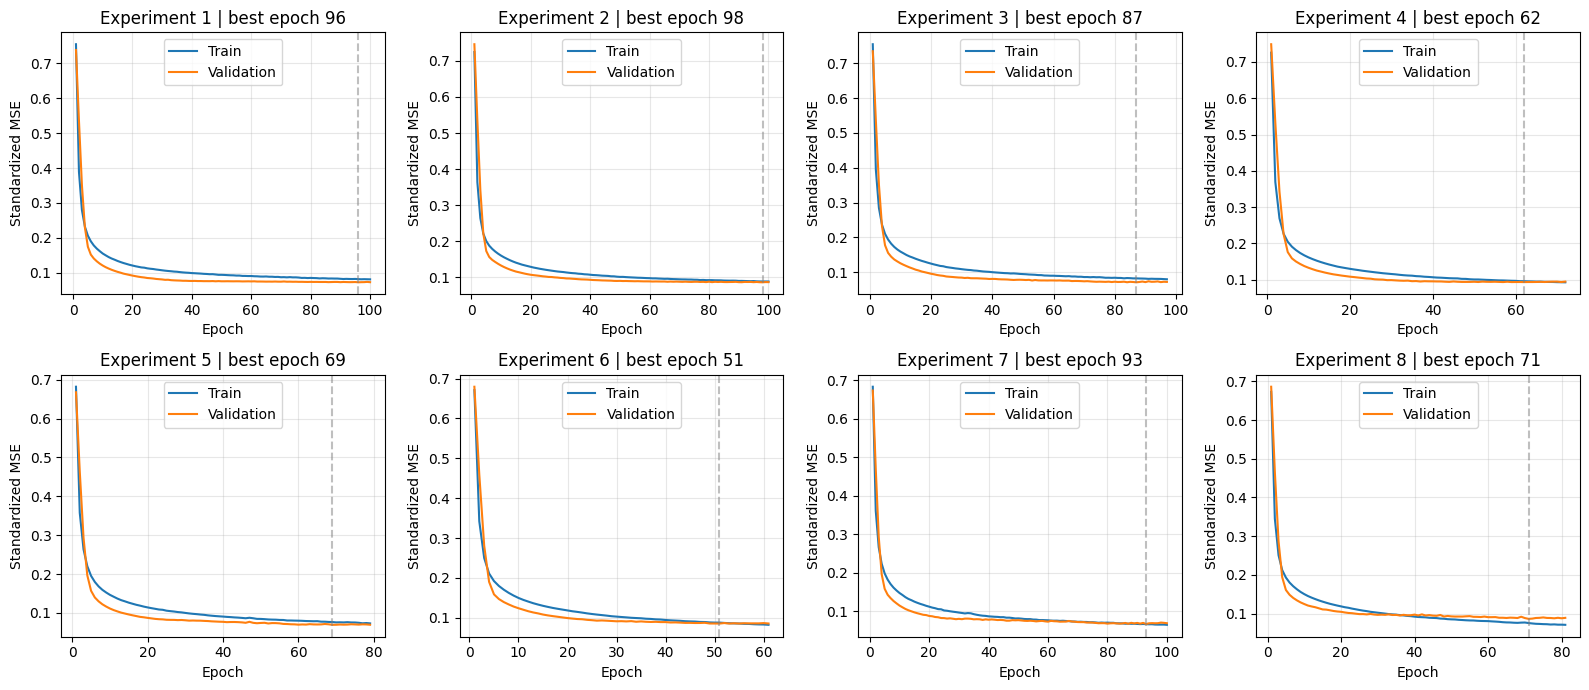

In [ ]:
import matplotlib.pyplot as plt
fig,axes=plt.subplots(2,4,figsize=(16,7))
for exp_id,ax in enumerate(axes.flat,1):
    h=pd.read_csv(batch_dir/f'experiment_{exp_id:02d}'/'training_log.csv')
    ax.plot(h['epoch']+1,h['loss'],label='Train')
    ax.plot(h['epoch']+1,h['val_loss'],label='Validation')
    best=int(np.argmin(h['val_loss'].to_numpy())+1)
    ax.axvline(best,color='gray',linestyle='--',alpha=.5)
    ax.set_title(f'Experiment {exp_id} | best epoch {best}')
    ax.set_xlabel('Epoch');ax.set_ylabel('Standardized MSE');ax.legend();ax.grid(alpha=.3)
fig.tight_layout();fig.savefig(batch_dir/'learning_curves.png',dpi=180);plt.show()

## 19 최종 평가와 필수 성능표

저장된 8개 모델을 같은 평가 집합에 적용하여 MAE·RMSE를 확인한다. 평가표가 이미 있으면 재사용하고, 새 실험 폴더에 없으면 저장 모델로 추론해 생성한다. 이 단계에서는 학습하지 않는다.

각 모델과 함께 저장한 scaler·분할을 그대로 사용한다. 평가 결과로 설정을 다시 고르지 않으며, 시각화 모델은 앞 단계의 검증 결과로 선택한다. 기본 지표는 실습과 같이 부재 차량 채움값까지 포함한 전체 7대 좌표 성분 기준이다. 원래 좌표 스케일의 지표는 별도로 표시한다.

In [ ]:
# 저장 모델과 동일한 평가 분할인지 먼저 확인
with np.load(batch_dir / 'split_indices.npz') as saved:
    for name, idx in [('train_idx', train_idx), ('val_idx', val_idx), ('test_idx', test_idx)]:
        assert np.array_equal(saved[name], idx), '저장 분할과 현재 분할이 다릅니다.'
assert json.loads((batch_dir / 'manifest.json').read_text(encoding='utf-8'))['protocol'] == 'course_required'

evaluation_path = batch_dir / 'test_results.csv'
required_columns = ['실험', 'LSTM 유닛', '과거(초)', '미래(초)',
                    'MAE_정규화', 'RMSE_정규화', 'MAE_원래좌표', 'RMSE_원래좌표']

if evaluation_path.is_file():
    # 기존 결과는 변경하지 않고 그대로 읽음
    test_results_df = pd.read_csv(evaluation_path)
    print('기존 평가표 재사용:', evaluation_path)
else:
    # 새 실험 또는 평가표 누락 시에만 저장 모델로 추론
    # fit()이나 scaler 재적합은 수행하지 않음
    evaluation_rows = []
    for _, row in experiment_df.iterrows():
        exp_id = int(row['실험'])
        exp_dir = batch_dir / f'experiment_{exp_id:02d}'
        cfg = json.loads((exp_dir / 'config.json').read_text(encoding='utf-8'))
        assert int(cfg['experiment']) == exp_id
        assert int(cfg['anchor_idx']) == ANCHOR_IDX, '저장 모델의 기준 시점이 다릅니다.'
        assert int(cfg['units']) == int(row['LSTM 유닛'])
        assert int(cfg['past_seconds']) == int(row['과거 관측(초)'])
        assert int(cfg['future_seconds']) == int(row['미래 예측(초)'])

        X_exp, y_exp, _, _ = make_xy(cfg['past_seconds'], cfg['future_seconds'])
        saved_scalers = joblib.load(exp_dir / 'scalers.joblib')
        X_test_raw = X_exp[test_idx]
        y_test_raw = y_exp[test_idx]
        X_test_scaled = saved_scalers['scaler_x'].transform(
            X_test_raw.reshape(-1, 14)
        ).reshape(X_test_raw.shape).astype(np.float32)
        y_test_scaled = saved_scalers['scaler_y'].transform(
            y_test_raw.reshape(-1, 14)
        ).reshape(y_test_raw.shape).astype(np.float32)

        tf.keras.backend.clear_session()
        evaluation_model = tf.keras.models.load_model(exp_dir / 'best_model.keras', compile=False)
        predicted_scaled = evaluation_model.predict(X_test_scaled, batch_size=64, verbose=0)
        if predicted_scaled.shape != y_test_scaled.shape:
            raise ValueError(f'실험 {exp_id}: 예측·정답 형상이 다릅니다.')
        predicted_raw = saved_scalers['scaler_y'].inverse_transform(
            predicted_scaled.reshape(-1, 14)
        ).reshape(predicted_scaled.shape)
        normalized_metrics = calculate_metrics(y_test_scaled, predicted_scaled)
        original_metrics = calculate_metrics(y_test_raw, predicted_raw)
        evaluation_rows.append({
            '실험': exp_id, 'LSTM 유닛': int(cfg['units']),
            '과거(초)': int(cfg['past_seconds']), '미래(초)': int(cfg['future_seconds']),
            'MAE_정규화': normalized_metrics['MAE'], 'RMSE_정규화': normalized_metrics['RMSE'],
            'MAE_원래좌표': original_metrics['MAE'], 'RMSE_원래좌표': original_metrics['RMSE']
        })
        print(f'실험 {exp_id}/8 최종 평가 완료 - 재학습 없음')
        del evaluation_model, X_exp, y_exp, X_test_raw, y_test_raw
        del X_test_scaled, y_test_scaled, predicted_scaled, predicted_raw

    # 8개 평가가 모두 성공한 뒤에만 결과 파일 생성
    test_results_df = pd.DataFrame(evaluation_rows)
    test_results_df.to_csv(evaluation_path, index=False, encoding='utf-8-sig')
    print('평가표 저장:', evaluation_path)

if not set(required_columns).issubset(test_results_df.columns):
    raise ValueError('평가표의 필수 열이 누락됐습니다.')
if len(test_results_df) != 8 or set(test_results_df['실험']) != set(range(1, 9)):
    raise ValueError('평가표가 실험 1~8을 각각 한 번씩 포함하는지 확인하세요.')
if not np.isfinite(test_results_df[required_columns[4:]].to_numpy(dtype=float)).all():
    raise ValueError('평가 지표에 NaN 또는 무한대가 있습니다.')

print('실습 방식의 최종 평가 결과 (정규화 좌표, 무단위)')
display(test_results_df[required_columns[:6]].round(4))
print('해석용 원래 좌표 스케일의 결과')
display(test_results_df[['실험', 'MAE_원래좌표', 'RMSE_원래좌표']].round(4))

## 20 실제 궤적과 예측 궤적

시각화 모델은 검증 RMSE로 예측 길이별 선택한다. 모델은 7대를 예측하지만 그림은 Ego 한 사례만 표시한다.

검증 결과로 선택한 모델의 실제·예측 미래를 같은 사례에서 비교한다.

시각화는 Ego 한 사례이고 모델은 7대를 예측한다. 좋은 사례를 선별한 결과가 아니며 한 사례가 전체 상황의 성능을 대표하지 않는다.


In [ ]:
# 테스트 점수가 아니라 검증 결과로 선정한 모델을 예측 길이별로 시각화
# 특정 사례를 좋은 결과로 골라내지 않고 평가 세트의 첫 시나리오를 사용
selected=pd.read_csv(batch_dir/'validation_selected_models.csv')
scenario=int(test_idx[0])
fig,axes=plt.subplots(1,len(selected),figsize=(6*len(selected),5),squeeze=False)
for ax,(_,row) in zip(axes.flat,selected.iterrows()):
    exp_id=int(row['실험']);exp_dir=batch_dir/f'experiment_{exp_id:02d}'
    cfg=json.loads((exp_dir/'config.json').read_text(encoding='utf-8'))
    X_exp,y_exp,_,_=make_xy(cfg['past_seconds'],cfg['future_seconds'])
    scalers=joblib.load(exp_dir/'scalers.joblib')
    observed=X_exp[scenario]
    xs=scalers['scaler_x'].transform(observed).astype(np.float32)[None]
    tf.keras.backend.clear_session();model=tf.keras.models.load_model(exp_dir/'best_model.keras')
    ps=model.predict(xs,verbose=0)[0]
    predicted=scalers['scaler_y'].inverse_transform(ps)
    ego=slice(2*EGO_IDX,2*EGO_IDX+2)
    obs=observed[:,ego];actual=y_exp[scenario,:,ego];pred=predicted[:,ego]
    ax.plot(obs[:,0],obs[:,1],'o-',label='Observed',markersize=3)
    ax.plot(actual[:,0],actual[:,1],'o-',label='Actual future',markersize=3)
    ax.plot(pred[:,0],pred[:,1],'--',label='Predicted future')
    ax.scatter([0],[0],c='black',marker='x',label='Prediction origin')
    ax.set_title(f'Experiment {exp_id} | future {cfg["future_seconds"]} s')
    ax.set_xlabel('Relative x (m)');ax.set_ylabel('Relative y (m)')
    ax.set_aspect('equal',adjustable='datalim');ax.grid(alpha=.3);ax.legend()
fig.suptitle(f'Ego trajectory | scenario index {scenario}')
fig.tight_layout();fig.savefig(batch_dir/'actual_vs_predicted.png',dpi=200);plt.show()
# 한 사례의 그림은 전체 성능을 대표하지 않으며 정지 장면일 수도 있음

### 20.1 전체 차량 슬롯의 실제·예측 궤적

실습 6의 19~20쪽처럼 한 시나리오의 Ego와 주변 차량을 같은 그림에 표시한다. 검증 성능으로 이미 선택한 3초·5초 모델을 사용하며, 앞의 Ego 사례 그림과 별도로 저장한다.

차량마다 색을 구분하고 과거는 점선, 실제 미래는 실선, 예측 미래는 파선으로 표시한다. 평가 집합에서 전체 71개 시점의 완전 관측 차량 수가 가장 많은 첫 사례를 선택한다. 이는 미래 관측 여부를 이용한 사후 설명용 선택이며 성능이 좋은 사례를 고르는 기준은 아니다. 7개는 차량 슬롯 수이며, 실제 부재 슬롯이나 결측 시점은 0 위치에 차량이 있는 것처럼 표시하지 않는다. 정답이 없는 시점의 예측도 이 비교 그림에서는 숨긴다. 한 그림을 전체 예측 성능으로 일반화하지 않는다.

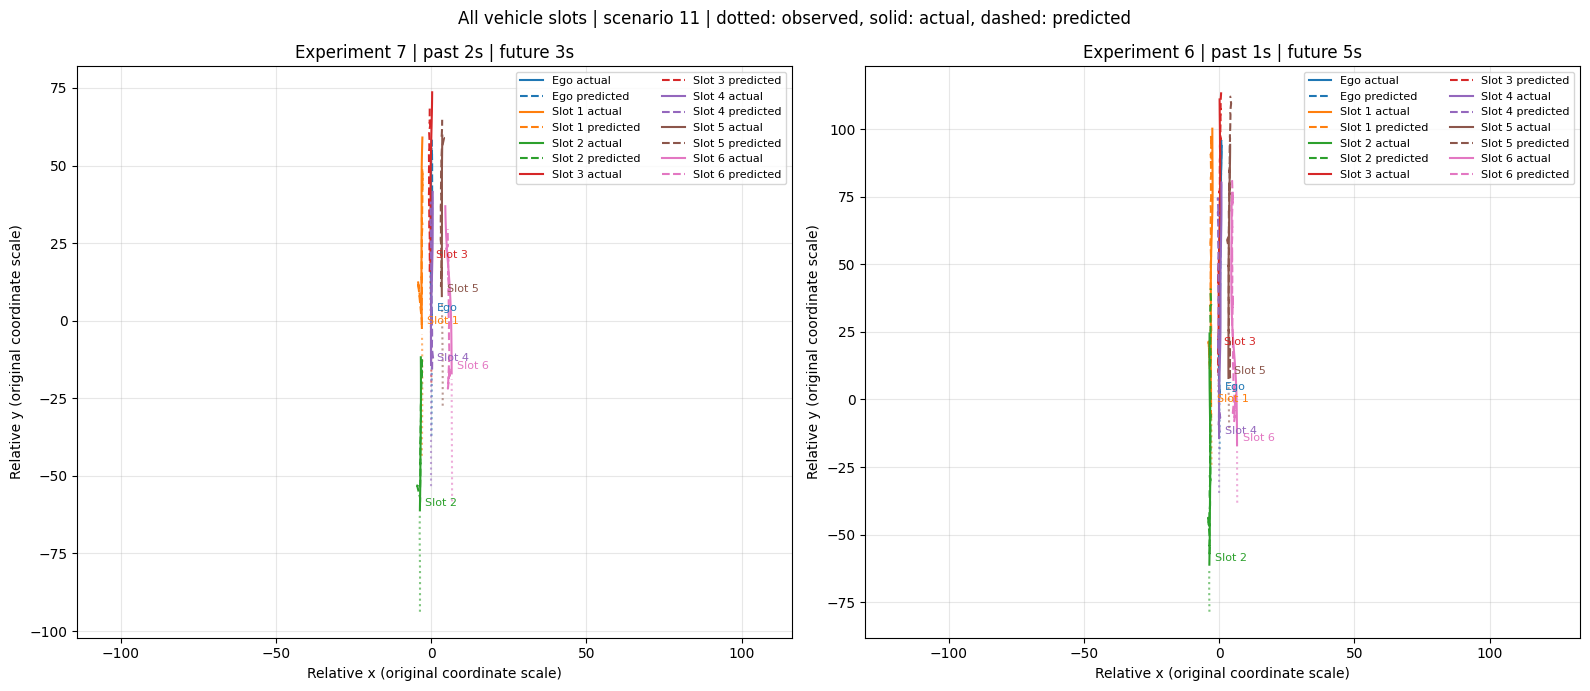

In [ ]:
# 기존 모델과 저장 scaler로만 추론 - 재학습 없음
selected = pd.read_csv(batch_dir / 'validation_selected_models.csv')
if selected.empty:
    raise ValueError('검증 기준 선택 모델이 없습니다.')

# 예측 오차와 무관하게 평가 집합 순서에서 완전 관측 차량이 가장 많은 사례 선택
# 첫 동률 사례를 사용하며 미래 정답을 이용한 사후 시각화용 선택임을 명시
valid_pairs = np.isfinite(xy_data[test_idx]).all(axis=-1)
complete_slots = valid_pairs.all(axis=-1)
scenario_position = int(np.argmax(complete_slots.sum(axis=1)))
all_vehicle_scenario = int(test_idx[scenario_position])
print('시각화 원본 시나리오:', all_vehicle_scenario)
print('전체 71개 시점에서 완전 관측된 차량 슬롯 수:', int(complete_slots[scenario_position].sum()))

fig, axes = plt.subplots(1, len(selected), figsize=(8 * len(selected), 7), squeeze=False)
colors = plt.get_cmap('tab10')
all_vehicle_plot_rows = []
for ax, (_, row) in zip(axes.flat, selected.iterrows()):
    exp_id = int(row['실험'])
    exp_dir = batch_dir / f'experiment_{exp_id:02d}'
    cfg = json.loads((exp_dir / 'config.json').read_text(encoding='utf-8'))
    X_plot, y_plot, X_plot_valid, y_plot_valid = make_xy(cfg['past_seconds'], cfg['future_seconds'])
    scalers = joblib.load(exp_dir / 'scalers.joblib')
    observed = X_plot[all_vehicle_scenario]
    actual = y_plot[all_vehicle_scenario]
    observed_mask = X_plot_valid[all_vehicle_scenario].reshape(-1, 7, 2).all(axis=-1)
    actual_mask = y_plot_valid[all_vehicle_scenario].reshape(-1, 7, 2).all(axis=-1)
    scaled_observed = scalers['scaler_x'].transform(observed).astype(np.float32)[None]
    tf.keras.backend.clear_session()
    plot_model = tf.keras.models.load_model(exp_dir / 'best_model.keras', compile=False)
    scaled_prediction = plot_model.predict(scaled_observed, verbose=0)[0]
    predicted = scalers['scaler_y'].inverse_transform(scaled_prediction).reshape(-1, 7, 2)
    observed = observed.reshape(-1, 7, 2)
    actual = actual.reshape(-1, 7, 2)

    for slot in range(7):
        valid_observed = observed_mask[:, slot]
        valid_future = actual_mask[:, slot]
        all_vehicle_plot_rows.append({
            '실험': exp_id, '시나리오': all_vehicle_scenario, '차량 슬롯': slot,
            '관측 유효 시점': int(valid_observed.sum()),
            '미래 유효 시점': int(valid_future.sum()),
            '표시': bool(valid_observed.any() or valid_future.any())
        })
        if not valid_observed.any() and not valid_future.any():
            continue
        color = colors(slot)
        label = 'Ego' if slot == EGO_IDX else f'Slot {slot}'
        # 결측 시점은 NaN으로 복원해 선이 부재 구간을 가로질러 이어지지 않게 함
        observed_line = np.where(valid_observed[:, None], observed[:, slot], np.nan)
        actual_line = np.where(valid_future[:, None], actual[:, slot], np.nan)
        predicted_line = np.where(valid_future[:, None], predicted[:, slot], np.nan)
        ax.plot(observed_line[:, 0], observed_line[:, 1], ':', color=color, alpha=0.6)
        ax.plot(actual_line[:, 0], actual_line[:, 1], '-', color=color, label=f'{label} actual')
        ax.plot(predicted_line[:, 0], predicted_line[:, 1], '--', color=color, label=f'{label} predicted')
        if valid_future.any():
            first = int(np.flatnonzero(valid_future)[0])
            ax.annotate(label, actual_line[first], fontsize=8, color=color,
                        xytext=(4, 3), textcoords='offset points')
    ax.set_title(f'Experiment {exp_id} | past {cfg["past_seconds"]}s | future {cfg["future_seconds"]}s')
    ax.set_xlabel('Relative x (original coordinate scale)')
    ax.set_ylabel('Relative y (original coordinate scale)')
    ax.set_aspect('equal', adjustable='datalim')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, ncol=2)
    del plot_model, X_plot, y_plot, X_plot_valid, y_plot_valid

fig.suptitle(f'All vehicle slots | scenario {all_vehicle_scenario} | dotted: observed, solid: actual, dashed: predicted')
fig.tight_layout()
fig.savefig(batch_dir / 'actual_vs_predicted_all_vehicles.png', dpi=200, bbox_inches='tight')
plt.show()
display(pd.DataFrame(all_vehicle_plot_rows))
# 정답이 부재한 시점은 실제·예측 선 모두 숨김. 0 채움값 포함 기본 성능표는 변경하지 않음.

## 21 예측 시점별·차로 상태별 추가 평가

저장된 8개 모델을 동일한 평가 시나리오에 적용하여 추가 오차를 계산한다.

- 기존 과제 지표와 같은 전체 7대의 정규화 MAE·RMSE를 재계산하여 확인한다.
- 추가 분석은 해석이 명확한 Ego 차량의 원래 좌표 성분 MAE·RMSE를 사용한다.
- 차로 상태는 기존 EDA와 동일하게 전체 7초 동안의 Lane_ID 변화 여부로 구분한다.
- 이 그룹 구분은 사후 결과 분석용이며 모델 입력이나 모델 선택에 사용하지 않는다.
- 추가 평가 결과를 보고 모델을 다시 선택하거나 튜닝하지 않는다.

같은 저장 모델의 기본 성능을 검산하고 시간·차로 상태별 Ego 오차를 계산한다.

차로 상태는 전체 7초의 Lane_ID 변화 여부다. 유지 1,914개, 변화 86개로 표본 크기가 다르며 변화 시점이 미래에 있다고 단정하지 않는다. 같은 시나리오·좌표 성분을 모아 각 예측 시점의 오차를 집계한다.


In [ ]:
from pathlib import Path
import json
import joblib
import tensorflow as tf

if "batch_dir" not in globals():
    raise RuntimeError("먼저 결과 경로 복원 셀을 실행하세요.")

extra_dir = Path(batch_dir)

extra_test_idx = np.load(
    extra_dir / "split_indices.npz"
)["test_idx"]

# 평가 집합의 차로 상태: 전체 71개 시점 기준
extra_test_groups = np.full(
    len(extra_test_idx), "Unknown", dtype=object
)

extra_test_groups[
    extra_lane_maintained[extra_test_idx]
] = "Maintained"

extra_test_groups[
    extra_lane_changed[extra_test_idx]
] = "Changed"

# 집단별 시나리오 수
extra_group_counts = (
    pd.Series(extra_test_groups, name="차로 상태")
    .value_counts()
    .rename("평가 시나리오 수")
    .to_frame()
)

display(extra_group_counts)

# 원본은 보존하고 평가 시나리오의 좌표만 복사
extra_test_xy = raw_data[
    extra_test_idx, :, :, 2:4
].copy()

extra_origin = extra_test_xy[
    :, 0, EXTRA_ANCHOR, :
][:, None, None, :]

extra_relative = extra_test_xy - extra_origin

extra_time_rows = []
extra_group_rows = []
extra_check_rows = []

for exp_id in range(1, 9):
    exp_dir = extra_dir / f"experiment_{exp_id:02d}"

    cfg = json.loads(
        (exp_dir / "config.json").read_text(
            encoding="utf-8"
        )
    )

    if int(cfg.get("anchor_idx", 20)) != EXTRA_ANCHOR:
        raise ValueError("저장 모델의 기준 시점이 다릅니다.")

    past = int(cfg["past_seconds"])
    future = int(cfg["future_seconds"])
    units = int(cfg["units"])

    n_input = round(past / EXTRA_DT) + 1
    n_future = round(future / EXTRA_DT)

    # 기존 학습 코드와 동일한 입력·정답 배열 순서
    X_extra = (
        extra_relative[
            :,
            :,
            EXTRA_ANCHOR - n_input + 1:EXTRA_ANCHOR + 1,
            :
        ]
        .transpose(0, 2, 1, 3)
        .reshape(len(extra_test_idx), n_input, 14)
    )

    y_extra = (
        extra_relative[
            :,
            :,
            EXTRA_ANCHOR + 1:EXTRA_ANCHOR + 1 + n_future,
            :
        ]
        .transpose(0, 2, 1, 3)
        .reshape(len(extra_test_idx), n_future, 14)
    )

    if np.isinf(X_extra).any() or np.isinf(y_extra).any():
        raise ValueError("평가 좌표에 무한대가 있습니다.")

    # Ego 좌표는 채움값 없이 평가할 수 있는지 확인
    if not np.isfinite(y_extra[:, :, :2]).all():
        raise ValueError("Ego 정답 좌표에 결측이 있습니다.")

    X_extra = np.nan_to_num(
        X_extra, nan=0.0
    ).astype(np.float32)

    y_extra = np.nan_to_num(
        y_extra, nan=0.0
    ).astype(np.float32)

    scalers = joblib.load(exp_dir / "scalers.joblib")

    X_scaled = scalers["scaler_x"].transform(
        X_extra.reshape(-1, 14)
    ).reshape(X_extra.shape).astype(np.float32)

    y_scaled = scalers["scaler_y"].transform(
        y_extra.reshape(-1, 14)
    ).reshape(y_extra.shape).astype(np.float32)

    tf.keras.backend.clear_session()

    extra_model = tf.keras.models.load_model(
        exp_dir / "best_model.keras",
        compile=False
    )

    # 학습 없이 평가 집합 추론
    pred_scaled = extra_model.predict(
        X_scaled, batch_size=64, verbose=0
    )

    pred_raw = scalers["scaler_y"].inverse_transform(
        pred_scaled.reshape(-1, 14)
    ).reshape(pred_scaled.shape)

    # 기존 전체 7대 정규화 지표 재확인
    normalized_error = (
        pred_scaled.astype(np.float64)
        - y_scaled.astype(np.float64)
    )

    extra_check_rows.append({
        "실험": exp_id,
        "MAE_정규화_재계산": np.abs(
            normalized_error
        ).mean(),
        "RMSE_정규화_재계산": np.sqrt(
            np.square(normalized_error).mean()
        )
    })

    # 추가 분석은 Ego의 x·y 좌표 성분만 사용
    ego_error = (
        pred_raw[:, :, :2].astype(np.float64)
        - y_extra[:, :, :2].astype(np.float64)
    )

    if not np.isfinite(ego_error).all():
        raise ValueError("예측 오차에 비정상 값이 있습니다.")

    # 미래 시점별 오차: 시나리오와 x·y 성분에 대해 집계
    time_mae = np.abs(ego_error).mean(axis=(0, 2))
    time_rmse = np.sqrt(
        np.square(ego_error).mean(axis=(0, 2))
    )

    for step in range(n_future):
        extra_time_rows.append({
            "실험": exp_id,
            "유닛": units,
            "과거(초)": past,
            "미래(초)": future,
            "예측 후 시간(초)": round(
                (step + 1) * EXTRA_DT, 1
            ),
            "Ego_MAE": time_mae[step],
            "Ego_RMSE": time_rmse[step]
        })

    # 그룹별 오차: 해당 집단의 전체 미래 시점·x·y 집계
    for group in ["Maintained", "Changed", "Unknown"]:
        mask = extra_test_groups == group

        if not mask.any():
            continue

        errors = ego_error[mask]

        extra_group_rows.append({
            "실험": exp_id,
            "유닛": units,
            "과거(초)": past,
            "미래(초)": future,
            "차로 상태": group,
            "시나리오 수": int(mask.sum()),
            "Ego_MAE": np.abs(errors).mean(),
            "Ego_RMSE": np.sqrt(
                np.square(errors).mean()
            )
        })

    print(f"실험 {exp_id}/8 추가 평가 완료")

    del extra_model, X_scaled, y_scaled
    del pred_scaled, pred_raw, ego_error

extra_time_df = pd.DataFrame(extra_time_rows)
extra_group_df = pd.DataFrame(extra_group_rows)
extra_check_df = pd.DataFrame(extra_check_rows)

# 기존 성능표와 재계산 결과를 나란히 확인
saved_results = pd.read_csv(
    extra_dir / "test_results.csv"
)

display(
    saved_results[
        ["실험", "MAE_정규화", "RMSE_정규화"]
    ]
    .merge(extra_check_df, on="실험")
    .round(6)
)

print("추가 평가 완료 — 모델 재학습 없음")

### 21.1 기본 평가 수치 재현 확인

표를 눈으로 비교하는 것에 더해, 저장된 MAE·RMSE와 재계산 값이 허용오차 내에서 일치하는지 확인한다.


In [ ]:
# 기본 성능 재현 확인: 표에 표시된 반올림 오차와 추론 수치 차이를 허용
check = saved_results[['실험', 'MAE_정규화', 'RMSE_정규화']].merge(extra_check_df, on='실험')
for metric in ['MAE', 'RMSE']:
    assert np.allclose(check[f'{metric}_정규화'], check[f'{metric}_정규화_재계산'], rtol=1e-4, atol=1e-5), f'{metric} 재계산 결과를 확인하세요.'
print('기존 전체 7대 정규화 평가 결과 재현 확인 완료')


### 21.2 예측 시간과 차로 상태별 오차 시각화

미래 예측 시점에 따라 Ego 좌표 오차가 어떻게 변하는지 확인하고,
동일 모델에서 차로 ID 유지·변화 집단의 오차를 비교한다.

현재 그래프는 Ego 차량의 원래 좌표 성분 오차이므로,
기존 전체 7대 정규화 MAE·RMSE 표와 구분한다.
집단 간 차이는 기술적 비교이며 통계적 유의성이나 인과관계를 뜻하지 않는다.

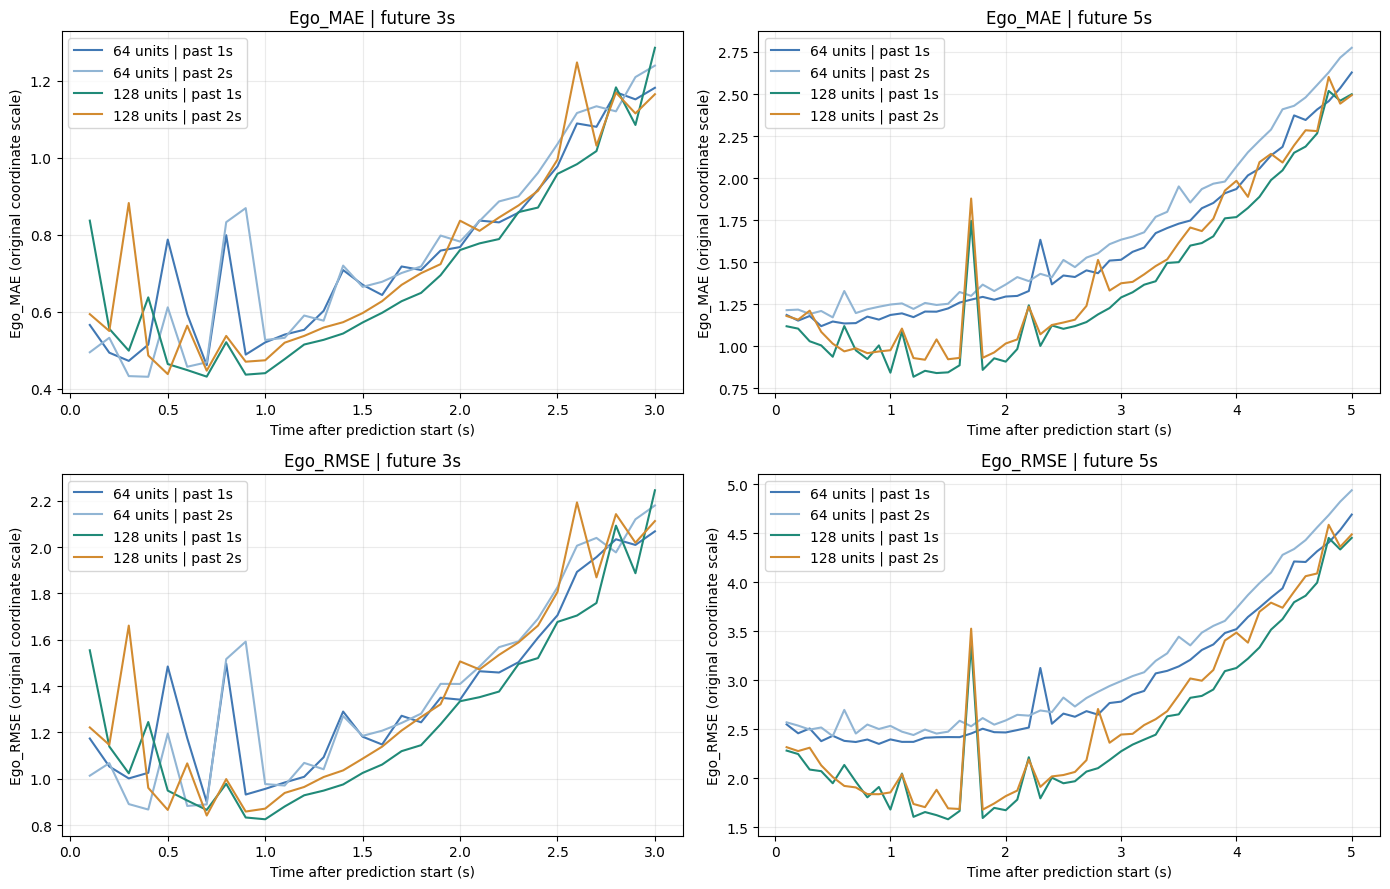

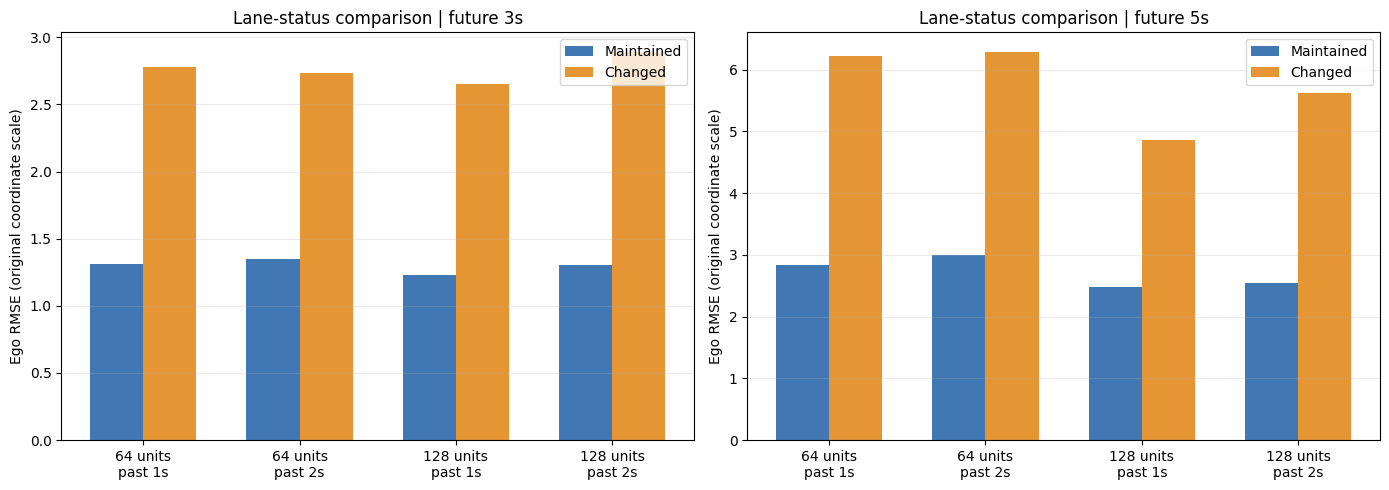

In [ ]:
# 예측 시점별 MAE·RMSE
# 미래 3초와 5초 모델을 별도 패널로 표시
fig, axes = plt.subplots(
    2, 2, figsize=(14, 9), squeeze=False
)

condition_colors = {
    (64, 1): "#4178B4",
    (64, 2): "#91B5D4",
    (128, 1): "#208A78",
    (128, 2): "#D28B30"
}

for col, future in enumerate([3, 5]):
    subset = extra_time_df.loc[
        extra_time_df["미래(초)"] == future
    ]

    for (units, past), group in subset.groupby(
        ["유닛", "과거(초)"]
    ):
        group = group.sort_values("예측 후 시간(초)")

        for row, metric in enumerate(
            ["Ego_MAE", "Ego_RMSE"]
        ):
            axes[row, col].plot(
                group["예측 후 시간(초)"],
                group[metric],
                color=condition_colors[(units, past)],
                label=f"{units} units | past {past}s"
            )

    for row, metric in enumerate(
        ["Ego_MAE", "Ego_RMSE"]
    ):
        ax = axes[row, col]

        ax.set_title(f"{metric} | future {future}s")
        ax.set_xlabel("Time after prediction start (s)")
        ax.set_ylabel(f"{metric} (original coordinate scale)")
        ax.grid(alpha=0.25)
        ax.legend()

fig.tight_layout()
plt.show()

# 차로 상태별 RMSE
fig, axes = plt.subplots(
    1, 2, figsize=(14, 5), squeeze=False
)

group_colors = {
    "Maintained": "#4178B4",
    "Changed": "#E69534"
}

for col, future in enumerate([3, 5]):
    ax = axes[0, col]

    subset = extra_group_df.loc[
        (extra_group_df["미래(초)"] == future)
        & extra_group_df["차로 상태"].isin(
            ["Maintained", "Changed"]
        )
    ]

    pivot = (
        subset.pivot(
            index=["유닛", "과거(초)"],
            columns="차로 상태",
            values="Ego_RMSE"
        )
        .reindex(
            pd.MultiIndex.from_tuples(
                [(64, 1), (64, 2), (128, 1), (128, 2)],
                names=["유닛", "과거(초)"]
            )
        )
        .reindex(columns=["Maintained", "Changed"])
    )

    positions = np.arange(len(pivot))
    width = 0.34

    for offset, group in [
        (-width / 2, "Maintained"),
        (width / 2, "Changed")
    ]:
        ax.bar(
            positions + offset,
            pivot[group],
            width=width,
            color=group_colors[group],
            label=group
        )

    ax.set_xticks(positions)
    ax.set_xticklabels([
        f"{units} units\npast {past}s"
        for units, past in pivot.index
    ])

    ax.set_title(f"Lane-status comparison | future {future}s")
    ax.set_ylabel("Ego RMSE (original coordinate scale)")
    ax.legend()
    ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
plt.show()

# 수치와 표본 수를 함께 확인
display(extra_group_df.round(4))

### 추가 평가 결과 해석

기존 전체 차량 정규화 MAE·RMSE와 재계산 결과가 표시 정밀도 내에서 일치하였다.

Ego 차량의 시점별 오차는 예측 초반에 감소한 뒤 후반으로 갈수록 증가하는
경향을 보였다. 따라서 전체 미래 구간을 합친 평균 지표만으로는 예측 시점별
성능 차이를 충분히 설명하기 어렵다.

차로 ID 변화 집단은 모든 실험 조건에서 유지 집단보다 높은 Ego RMSE를 보였다.
평가 시나리오는 유지 1,914개, 변화 86개로 집단 크기에 차이가 있었다.
두 집단은 속도·가속도 분포도 다르므로, 관측된 오차 차이를 차로 변화의
독립적인 인과 효과로 해석하지 않는다.

차로 상태는 전체 7초 구간의 Lane_ID 변화 여부로 분류하였다.
따라서 변화 집단의 모든 사례에서 미래 예측 구간에 차로 변화가 발생했다고
단정할 수는 없다.

추가 지표는 Ego 차량의 원래 좌표 성분 오차이며, 과제 기본 결과인
전체 7대 차량의 정규화 MAE·RMSE와 구분한다.

## 22 정지·감속 상황의 예측 실패

교통안전·모빌리티 분야의 모델 검증 관점에서 정지·감속 상황의 예측 오차를 확인한다.

- 모델은 기존 검증 결과로 선택한 모델을 사용한다.
- 미래 정지: 예측 대상 미래 구간의 속도가 모두 0인 시나리오.
- 미래 감속: 미래 정지가 아니면서, 미래 마지막 속도가 기준 시점보다 낮고
  미래 구간 평균 가속도가 음수인 시나리오.
- 나머지 유효 시나리오는 기타로 분류한다.
- 상황 분류는 미래 실제값을 사용하는 사후 분석이며, 실시간 탐지 결과가 아니다.
- 예측 길이에 따라 같은 시나리오의 상황 분류가 달라질 수 있다.

시나리오별 Ego MAE의 중앙값·90백분위수와 집단 전체 RMSE를 확인한다.
또한 마지막 예측 시점의 종방향 위치 오차를 확인한다.

종방향 오차는 예측 y − 실제 y로 정의한다.
양수는 더 큰 y 위치를 예측했다는 의미이며, 사고 위험이나 충돌 가능성을 뜻하지 않는다.

정지·감속 집단에서 평균 오차뿐 아니라 큰 오차와 종방향 편향을 살펴본다.

실제 미래값으로 구분한 사후 분석이며 실시간 탐지가 아니다. 예측 길이에 따라 그룹이 달라진다. y 과대예측은 예측 y가 실제 y보다 크다는 뜻으로 사고·충돌 위험을 뜻하지 않는다.


In [ ]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import joblib
from IPython.display import display

# ① 저장 결과와 평가 자료 준비
if "raw_data" not in globals() or "batch_dir" not in globals():
    raise RuntimeError("먼저 데이터와 결과 경로 복원 셀을 실행하세요.")

job_dir = Path(batch_dir)

# 평가 성능을 보고 다시 고르지 않고,
# 기존에 검증 성능으로 선택한 모델을 사용
job_selected = pd.read_csv(
    job_dir / "validation_selected_models.csv"
).sort_values("미래(초)")

job_test_idx = np.load(
    job_dir / "split_indices.npz"
)["test_idx"]

job_summary_rows = []
job_scenario_rows = []
job_prediction_store = {}

job_dt = 0.1

for _, selected_row in job_selected.iterrows():
    exp_id = int(selected_row["실험"])
    exp_dir = job_dir / f"experiment_{exp_id:02d}"

    cfg = json.loads(
        (exp_dir / "config.json").read_text(encoding="utf-8")
    )

    anchor = int(cfg.get("anchor_idx", 20))
    past = int(cfg["past_seconds"])
    future = int(cfg["future_seconds"])

    n_input = round(past / job_dt) + 1
    n_future = round(future / job_dt)

    # ─────────────────────────────────
    # ② 미래 실제 주행 상태로 사후 그룹 분류
    # ─────────────────────────────────
    speed_at_anchor = raw_data[
        job_test_idx, 0, anchor, 7
    ]

    future_speed = raw_data[
        job_test_idx,
        0,
        anchor + 1:anchor + 1 + n_future,
        7
    ]

    future_acc = raw_data[
        job_test_idx,
        0,
        anchor + 1:anchor + 1 + n_future,
        8
    ]

    speed_valid = (
        np.isfinite(speed_at_anchor)
        & np.isfinite(future_speed).all(axis=1)
    )

    acc_valid = np.isfinite(future_acc).all(axis=1)

    stopped = (
        speed_valid
        & np.all(future_speed == 0, axis=1)
    )

    # 아주 작은 수치 차이를 감속으로 분류하지 않기 위한 허용오차
    numerical_tolerance = 1e-6

    decelerating = (
        speed_valid
        & acc_valid
        & ~stopped
        & (
            future_speed[:, -1]
            < speed_at_anchor - numerical_tolerance
        )
        & (future_acc.mean(axis=1) < 0)
    )

    situation = np.full(
        len(job_test_idx), "Unknown", dtype=object
    )

    situation[speed_valid & acc_valid] = "Other"
    situation[decelerating] = "Decelerating"
    situation[stopped] = "Stopped"

    # ─────────────────────────────────
    # ③ 기존 학습 방식과 동일한 좌표 입력 구성
    # ─────────────────────────────────
    xy = raw_data[job_test_idx, :, :, 2:4].copy()

    origin = xy[:, 0, anchor, :][:, None, None, :]
    relative = xy - origin

    observed = (
        relative[
            :, :, anchor - n_input + 1:anchor + 1, :
        ]
        .transpose(0, 2, 1, 3)
        .reshape(len(job_test_idx), n_input, 14)
    )

    actual = (
        relative[
            :, :, anchor + 1:anchor + 1 + n_future, :
        ]
        .transpose(0, 2, 1, 3)
        .reshape(len(job_test_idx), n_future, 14)
    )

    if np.isinf(observed).any() or np.isinf(actual).any():
        raise ValueError("좌표에 무한대가 있습니다.")

    # Ego는 실제 관측값으로 평가
    if not np.isfinite(actual[:, :, :2]).all():
        raise ValueError("Ego 정답 좌표에 결측이 있습니다.")

    observed = np.nan_to_num(
        observed, nan=0.0
    ).astype(np.float32)

    actual = np.nan_to_num(
        actual, nan=0.0
    ).astype(np.float32)

    scalers = joblib.load(exp_dir / "scalers.joblib")

    observed_scaled = scalers["scaler_x"].transform(
        observed.reshape(-1, 14)
    ).reshape(observed.shape).astype(np.float32)

    tf.keras.backend.clear_session()

    job_model = tf.keras.models.load_model(
        exp_dir / "best_model.keras",
        compile=False
    )

    predicted_scaled = job_model.predict(
        observed_scaled,
        batch_size=64,
        verbose=0
    )

    predicted = scalers["scaler_y"].inverse_transform(
        predicted_scaled.reshape(-1, 14)
    ).reshape(predicted_scaled.shape)

    # ─────────────────────────────────
    # ④ Ego의 시나리오별 오차
    # ─────────────────────────────────
    ego_actual = actual[:, :, :2].astype(np.float64)
    ego_predicted = predicted[:, :, :2].astype(np.float64)

    error = ego_predicted - ego_actual

    if not np.isfinite(error).all():
        raise ValueError("예측 오차에 비정상 값이 있습니다.")

    # 각 시나리오의 전체 미래 시점·x/y 성분 평균 오차
    scenario_mae = np.abs(error).mean(axis=(1, 2))

    # 마지막 미래 시점의 종방향 위치 오차
    final_y_error = error[:, -1, 1]

    scenario_table = pd.DataFrame({
        "실험": exp_id,
        "미래(초)": future,
        "원본 시나리오": job_test_idx,
        "상황": situation,
        "Ego_MAE": scenario_mae,
        "마지막_y오차": final_y_error
    })

    job_scenario_rows.append(scenario_table)

    # ─────────────────────────────────
    # ⑤ 그룹별 평균·꼬리 오차·방향 편향 요약
    # ─────────────────────────────────
    for group in [
        "Stopped", "Decelerating", "Other", "Unknown"
    ]:
        mask = situation == group

        if not mask.any():
            continue

        group_error = error[mask]

        job_summary_rows.append({
            "실험": exp_id,
            "미래(초)": future,
            "상황": group,
            "시나리오 수": int(mask.sum()),
            "MAE_평균": scenario_mae[mask].mean(),
            "MAE_중앙값": np.median(scenario_mae[mask]),
            "MAE_P90": np.quantile(
                scenario_mae[mask], 0.90
            ),
            "집단_RMSE": np.sqrt(
                np.square(group_error).mean()
            ),
            "마지막_y오차_평균": final_y_error[mask].mean(),
            "마지막_y과대예측률(%)": (
                final_y_error[mask] > numerical_tolerance
            ).mean() * 100
        })

    # 다음 사례 시각화에 사용할 실제 배열 보관
    job_prediction_store[exp_id] = {
        "future": future,
        "observed": observed[:, :, :2],
        "actual": ego_actual,
        "predicted": ego_predicted,
        "scenario_table": scenario_table
    }

    print(
        f"실험 {exp_id} · 미래 {future}초 "
        "상황별 분석 완료"
    )

    del job_model, observed_scaled, predicted_scaled

job_summary_df = pd.DataFrame(job_summary_rows)

job_scenario_df = pd.concat(
    job_scenario_rows, ignore_index=True
)

display(job_summary_df.round(4))

### 22.1 상황별 분포와 큰 오차 사례

정지·감속·기타 집단의 시나리오별 MAE 및 마지막 종방향 위치 오차를 비교한다.
평균뿐 아니라 오차 분포와 집단별 시나리오 수도 함께 확인한다.

정지·감속 집단에서 MAE가 가장 큰 사례를 실패 사례로 표시한다.
이는 의도적으로 선택한 큰 오차 사례이며, 전체 성능을 대표하지 않는다.

In [ ]:
# ① 상황별 오차 분포
job_group_order = [
    "Stopped", "Decelerating", "Other"
]

job_colors = {
    "Stopped": "#C75B54",
    "Decelerating": "#E6A23C",
    "Other": "#4178B4"
}

job_experiments = list(job_prediction_store)

fig, axes = plt.subplots(
    len(job_experiments),
    2,
    figsize=(14, 4.5 * len(job_experiments)),
    squeeze=False
)

for row_idx, exp_id in enumerate(job_experiments):
    table = job_prediction_store[exp_id]["scenario_table"]
    future = job_prediction_store[exp_id]["future"]

    present_groups = [
        group for group in job_group_order
        if (table["상황"] == group).any()
    ]

    labels = [
        f"{group}\n(n={(table['상황'] == group).sum():,})"
        for group in present_groups
    ]

    for col_idx, metric, ylabel in [
        (0, "Ego_MAE", "Scenario Ego MAE"),
        (1, "마지막_y오차", "Final longitudinal error")
    ]:
        ax = axes[row_idx, col_idx]

        values = [
            table.loc[table["상황"] == group, metric].to_numpy()
            for group in present_groups
        ]

        box = ax.boxplot(
            values,
            patch_artist=True,
            showfliers=True,
            flierprops={
                "marker": ".",
                "markersize": 3,
                "alpha": 0.25
            },
            medianprops={"color": "black"}
        )

        for patch, group in zip(
            box["boxes"], present_groups
        ):
            patch.set_facecolor(job_colors[group])
            patch.set_alpha(0.65)

        ax.set_xticks(
            range(1, len(present_groups) + 1)
        )
        ax.set_xticklabels(labels)
        ax.set_title(
            f"Experiment {exp_id} | future {future}s"
        )
        ax.set_ylabel(f"{ylabel} (original coordinate scale)")
        ax.grid(axis="y", alpha=0.25)

        if col_idx == 1:
            ax.axhline(
                0, color="black", linestyle="--", alpha=0.6
            )

fig.tight_layout()
plt.show()

# ② 정지·감속 집단에서 MAE가 가장 큰 사례
job_failure_cases = []

for exp_id in job_experiments:
    stored = job_prediction_store[exp_id]
    table = stored["scenario_table"]

    for group in ["Stopped", "Decelerating"]:
        subset = table.loc[table["상황"] == group]

        if subset.empty:
            continue

        # 큰 오차를 의도적으로 골라 실패 양상을 확인
        position = int(subset["Ego_MAE"].idxmax())

        job_failure_cases.append(
            (exp_id, group, position)
        )

if job_failure_cases:
    fig, axes = plt.subplots(
        1,
        len(job_failure_cases),
        figsize=(5 * len(job_failure_cases), 5),
        squeeze=False
    )

    for ax, (exp_id, group, position) in zip(
        axes.flat, job_failure_cases
    ):
        stored = job_prediction_store[exp_id]
        row = stored["scenario_table"].loc[position]

        for points, label, color, linestyle in [
            (
                stored["observed"][position],
                "Observed", "#4178B4", "-"
            ),
            (
                stored["actual"][position],
                "Actual future", "#E69534", "-"
            ),
            (
                stored["predicted"][position],
                "Predicted future", "#24958B", "--"
            )
        ]:
            ax.plot(
                points[:, 0],
                points[:, 1],
                linestyle=linestyle,
                color=color,
                marker=".",
                markersize=3,
                label=label
            )

        ax.set_title(
            f"Exp {exp_id} | {group}\n"
            f"Scenario {int(row['원본 시나리오'])} | "
            f"MAE {row['Ego_MAE']:.3f}"
        )
        ax.set_xlabel("Relative x (original coordinate scale)")
        ax.set_ylabel("Relative y (original coordinate scale)")
        ax.set_aspect("equal", adjustable="datalim")
        ax.legend()
        ax.grid(alpha=0.25)

    fig.tight_layout()
    plt.show()

### 22.2 속도값 기준 정지 집단의 좌표 검산

속도값과 좌표가 일관되는지 확인한다. 원본 값은 수정하지 않는다.

In [ ]:
# 속도값 기준 정지 사례에서 실제 좌표가 얼마나 변하는지 확인
stop_coordinate_checks = []

for exp_id, stored in job_prediction_store.items():
    table = stored["scenario_table"]

    stopped_positions = table.index[
        table["상황"] == "Stopped"
    ]

    for position in stopped_positions:
        # 현재 코드에서 Ego의 관측 마지막 상대좌표는 원점
        origin = stored["observed"][position, -1]
        actual = stored["actual"][position]

        displacement = actual - origin

        stop_coordinate_checks.append({
            "실험": exp_id,
            "원본 시나리오": int(
                table.loc[position, "원본 시나리오"]
            ),
            "실제_마지막_x변위": displacement[-1, 0],
            "실제_마지막_y변위": displacement[-1, 1],
            "실제_최대이동거리": np.linalg.norm(
                displacement, axis=1
            ).max()
        })

stop_coordinate_check_df = pd.DataFrame(
    stop_coordinate_checks
)

display(
    stop_coordinate_check_df
    .sort_values("실제_최대이동거리", ascending=False)
    .head(10)
    .round(4)
)

### 22.3 정지 좌표 검산의 최종 확인

상위 10개 표뿐 아니라 전체 정지 사례를 대상으로 마지막 종방향 변위가 0인지 확인한다.


In [ ]:
print(
    "전체 정지 사례의 마지막 종방향 변위가 0:",
    np.allclose(
        stop_coordinate_check_df["실제_마지막_y변위"],
        0,
        atol=1e-6
    )
)

미래 속도값이 모두 0인 집단의 좌표를 추가 확인한 결과,
최대 좌표 변위는 원래 좌표 스케일에서 약 0.1535였으며
마지막 종방향 변위는 모두 0이었다.

이 집단에서 모델의 마지막 종방향 위치 오차 평균은
3초 예측에서 +1.7370, 5초 예측에서 +4.4850이었다.
실제 종방향 이동이 없는 사례에서도 모델이 전진을 예측하는 편향이 관찰되었다.

다만 정지 집단의 평균 MAE가 다른 집단보다 가장 큰 것은 아니므로,
이 결과는 전체 정확도의 열세보다 특정 상황에서의 오차 방향을 보여준다.

## 23 좌표별 예측 오차 요약

기존 검증 결과로 선택한 3초·5초 모델의 Ego 예측 오차를 분석한다.
오차는 예측값 − 실제값으로 정의하며, 원래 좌표 스케일을 사용한다.

- 평균 오차: 특정 방향으로 치우치는지 확인.
- MAE·RMSE: 좌표별 오차 크기 확인.
- 오차 분포와 예측값 대비 산점도: 비대칭·극단값·퍼짐의 변화 확인.
- 시간별 평균과 분위수: 예측 구간에 따른 편향·오차 분포 변화 확인.

반복 시점과 중첩 시나리오를 독립 표본으로 간주한 통계적 검정은 수행하지 않는다.

좌표별 오차의 방향·크기·꼬리와 미래 시점별 퍼짐을 확인한다.

오차 부호는 예측−실제다. 음영은 시나리오 간 오차의 중앙 80% 경험 범위이며 신뢰구간·예측구간이 아니다. LSTM에 선형회귀 가정을 적용해 합격·불합격을 판정하는 검정은 하지 않는다.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

if "job_prediction_store" not in globals():
    raise RuntimeError(
        "먼저 정지·감속 상황별 추가 분석 셀을 실행하세요."
    )

residual_store = {}
residual_summary_rows = []

for exp_id, stored in job_prediction_store.items():
    actual = np.asarray(
        stored["actual"], dtype=np.float64
    )
    predicted = np.asarray(
        stored["predicted"], dtype=np.float64
    )

    if actual.shape != predicted.shape:
        raise ValueError("실제값과 예측값의 형상이 다릅니다.")

    if not (
        np.isfinite(actual).all()
        and np.isfinite(predicted).all()
    ):
        raise ValueError("실제값 또는 예측값에 비정상 값이 있습니다.")

    # 양수: 실제보다 큰 좌표를 예측
    # 음수: 실제보다 작은 좌표를 예측
    residual = predicted - actual

    residual_store[exp_id] = {
        "future": stored["future"],
        "predicted": predicted,
        "residual": residual
    }

    for coordinate, name in [(0, "x"), (1, "y")]:
        values = residual[:, :, coordinate]

        residual_summary_rows.append({
            "실험": exp_id,
            "미래(초)": stored["future"],
            "좌표": name,
            "시나리오 수": actual.shape[0],
            "예측 시점 수": actual.shape[1],
            "평균오차_편향": values.mean(),
            "중앙값오차": np.median(values),
            "MAE": np.abs(values).mean(),
            "RMSE": np.sqrt(np.square(values).mean()),
            "절대오차_P90": np.quantile(
                np.abs(values), 0.90
            ),
            "절대오차_P99": np.quantile(
                np.abs(values), 0.99
            )
        })

residual_summary_df = pd.DataFrame(
    residual_summary_rows
)

display(residual_summary_df.round(4))

### 23.1 오차 분포와 예측값 대비 오차

오차 분포가 0을 중심으로 형성되는지, 한쪽으로 치우치거나 긴 꼬리가 있는지 확인한다.
예측값 대비 오차 산점도에서는 좌표 범위에 따라 오차의 중심과 퍼짐이 달라지는지 살펴본다.

히스토그램과 요약 통계는 전체 값을 사용한다.
산점도만 가독성을 위해 최대 10,000개 점을 고정 난수로 추출한다.
오차의 퍼짐이 일정하지 않더라도 LSTM 분석이 무효가 되는 것은 아니다.

In [ ]:
for exp_id, stored in residual_store.items():
    residual = stored["residual"]
    predicted = stored["predicted"]
    future = stored["future"]

    fig, axes = plt.subplots(
        2, 2, figsize=(13, 8)
    )

    # 그림 표시용 표본만 추출
    # 통계 계산이나 원본 데이터에는 영향을 주지 않음
    point_count = residual.shape[0] * residual.shape[1]

    rng = np.random.default_rng(42)
    sampled_positions = rng.choice(
        point_count,
        size=min(10000, point_count),
        replace=False
    )

    for coordinate, name in [(0, "x"), (1, "y")]:
        errors = residual[:, :, coordinate].ravel()
        fitted = predicted[:, :, coordinate].ravel()

        # 위쪽: 전체 오차 분포
        ax = axes[0, coordinate]

        ax.hist(
            errors,
            bins=80,
            color="#4178B4",
            alpha=0.8
        )

        ax.axvline(
            0,
            color="black",
            linestyle="--",
            label="Zero error"
        )

        ax.axvline(
            errors.mean(),
            color="#D47732",
            label="Mean error"
        )

        ax.set_title(f"{name} error distribution")
        ax.set_xlabel(
            f"Predicted {name} - actual {name}"
        )
        ax.set_ylabel("Coordinate observations")
        ax.legend()
        ax.grid(alpha=0.2)

        # 아래쪽: 예측값 대비 오차
        ax = axes[1, coordinate]

        ax.scatter(
            fitted[sampled_positions],
            errors[sampled_positions],
            s=7,
            alpha=0.15,
            color="#208A78",
            edgecolors="none"
        )

        ax.axhline(
            0,
            color="black",
            linestyle="--"
        )

        ax.set_title(f"Predicted {name} vs error")
        ax.set_xlabel(
            f"Predicted {name} (original coordinate scale)"
        )
        ax.set_ylabel(
            f"{name} error (original coordinate scale)"
        )
        ax.grid(alpha=0.2)

    fig.suptitle(
        f"Prediction error diagnostics | "
        f"experiment {exp_id} | future {future}s"
    )

    fig.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

### 23.2 예측 시간별 편향과 분위수

각 미래 시점에서 평가 시나리오 전체의 평균 오차와 10~90백분위 범위를 표시한다.

- 평균선이 0에서 멀어지면 해당 방향의 예측 편향이 커지는 것으로 해석한다.
- 음영이 넓어지면 시나리오 간 오차의 퍼짐이 커지는 것으로 해석한다.
- 음영은 관측된 오차의 중앙 80% 범위이며 신뢰구간이나 보정된 예측구간이 아니다.
- 각 시점의 분포를 계산하며 서로 다른 시나리오를 연결하지 않는다.

In [ ]:
experiment_ids = list(residual_store)

fig, axes = plt.subplots(
    2,
    len(experiment_ids),
    figsize=(7 * len(experiment_ids), 8),
    squeeze=False
)

time_bias_rows = []

for col, exp_id in enumerate(experiment_ids):
    stored = residual_store[exp_id]
    residual = stored["residual"]
    future = stored["future"]

    times = (
        np.arange(1, residual.shape[1] + 1) * 0.1
    )

    for row, name in [(0, "x"), (1, "y")]:
        values = residual[:, :, row]

        # 같은 예측 시점에서 시나리오 간 오차 분포 계산
        mean_error = values.mean(axis=0)
        lower = np.quantile(values, 0.10, axis=0)
        upper = np.quantile(values, 0.90, axis=0)

        ax = axes[row, col]

        ax.fill_between(
            times,
            lower,
            upper,
            color="#8FB8D8",
            alpha=0.4,
            label="10th-90th percentile"
        )

        ax.plot(
            times,
            mean_error,
            color="#193B56",
            linewidth=2,
            label="Mean error"
        )

        ax.axhline(
            0,
            color="black",
            linestyle="--",
            alpha=0.6
        )

        ax.set_title(
            f"{name} error | experiment {exp_id} "
            f"| future {future}s"
        )
        ax.set_xlabel("Time after prediction start (s)")
        ax.set_ylabel(
            f"{name} error (original coordinate scale)"
        )
        ax.legend()
        ax.grid(alpha=0.2)

        for step, time in enumerate(times):
            time_bias_rows.append({
                "실험": exp_id,
                "미래(초)": future,
                "좌표": name,
                "예측 후 시간(초)": round(float(time), 1),
                "평균오차": mean_error[step],
                "오차_P10": lower[step],
                "오차_P90": upper[step]
            })

fig.tight_layout()
plt.show()

time_bias_df = pd.DataFrame(time_bias_rows)

# 각 모델의 마지막 미래 시점 결과 요약
display(
    time_bias_df.loc[
        np.isclose(
            time_bias_df["예측 후 시간(초)"],
            time_bias_df["미래(초)"]
        )
    ].round(4)
)

### 예측 오차 진단 결과

두 모델 모두 횡방향 평균 오차는 0에 가까웠으나, 종방향 평균 오차는
양수로 나타나 실제보다 큰 종방향 위치를 예측하는 평균 편향이 관찰되었다.

시간별 오차 분포에서는 예측 후반으로 갈수록 10~90백분위 범위가
확대되었다. 이는 평균 오차만으로 개별 시나리오의 예측 불확실성을
충분히 설명하기 어렵다는 점을 보여준다.

종방향 오차의 크기는 횡방향보다 컸지만, 두 방향의 이동 범위 차이도
있으므로 이를 좌표별 학습 능력의 차이로 단정하지 않는다.

오차 분포는 중심부에 집중되면서 큰 오차를 갖는 꼬리도 나타났다.
또한 오차의 퍼짐이 시간·예측값에 따라 달라지는 패턴이 관찰되었다.
이는 기술적 진단 결과이며, 등분산성·정규성 검정 결과는 아니다.

3초와 5초 결과는 서로 다른 선택 모델의 결과이므로 차이를
예측 길이만의 독립적인 효과로 해석하지 않는다.
음영은 경험적 오차의 중앙 80% 범위이며 신뢰구간이 아니다.

## 24 일정속도 기준 모델 비교

검증 결과로 선택한 LSTM 모델과 일정속도 기준 모델을 동일한 평가 사례에서 비교한다.

- 일정속도는 관측 마지막 1초의 좌표 변위를 1초로 나누어 계산한다.
- 관측 마지막 위치에서 해당 속도가 유지된다고 가정하여 미래 좌표를 예측한다.
- 미래 실제값과 속도 특성은 기준 모델의 입력에 사용하지 않는다.
- 두 모델 모두 같은 Ego 차량·미래 구간·원래 좌표 성분 MAE·RMSE로 평가한다.
- 이 비교는 과제 기본 평가표와 구분되는 추가 분석이다.

단순한 일정속도 예측보다 선택 LSTM이 유리한지 동일 평가 조건에서 비교한다.

속도는 최근 1초의 관측 좌표 변위로만 추정한다. 실제 미래를 사용하지 않는다. 가까운 미래에서 기준 모델이 더 나은 시점도 있고, 전체 구간 우열과 모든 시점의 우열은 다르다.


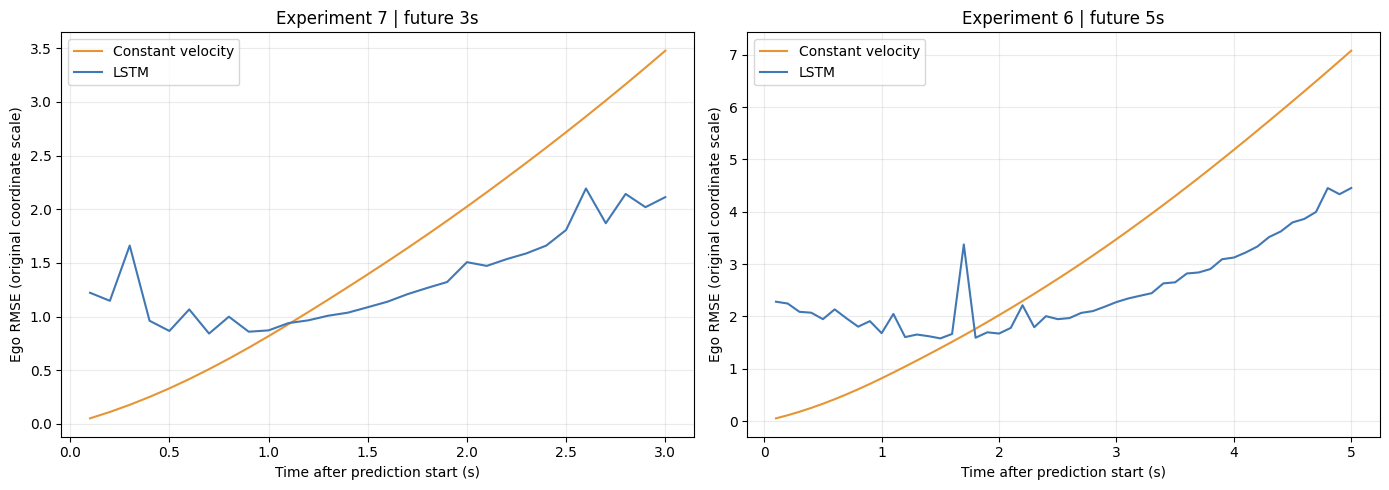

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

if "job_prediction_store" not in globals():
    raise RuntimeError(
        "먼저 정지·감속 상황별 추가 분석 셀을 실행하세요."
    )

baseline_rows = []
baseline_time_rows = []

for exp_id, stored in job_prediction_store.items():
    observed = np.asarray(
        stored["observed"], dtype=np.float64
    )
    actual = np.asarray(
        stored["actual"], dtype=np.float64
    )
    lstm_prediction = np.asarray(
        stored["predicted"], dtype=np.float64
    )

    if observed.shape[1] < 11:
        raise ValueError("최근 1초의 관측 좌표가 필요합니다.")

    if actual.shape != lstm_prediction.shape:
        raise ValueError("정답과 LSTM 예측의 형상이 다릅니다.")

    if not all(
        np.isfinite(a).all()
        for a in [observed, actual, lstm_prediction]
    ):
        raise ValueError("Ego 좌표에 비정상 값이 있습니다.")

    # 0.1초 간격의 11개 관측점은 처음~끝 간격이 1초
    # 모델마다 동일하게 최근 1초만 속도 추정에 사용
    estimated_velocity = (
        observed[:, -1, :] - observed[:, -11, :]
    ) / 1.0

    # 미래 첫 정답은 기준 시점으로부터 0.1초 뒤
    future_times = (
        np.arange(1, actual.shape[1] + 1) * 0.1
    )

    constant_velocity_prediction = (
        observed[:, -1:, :]
        + estimated_velocity[:, None, :]
        * future_times[None, :, None]
    )

    for model_name, prediction in [
        ("Constant velocity", constant_velocity_prediction),
        ("LSTM", lstm_prediction)
    ]:
        error = prediction - actual

        baseline_rows.append({
            "실험": exp_id,
            "미래(초)": stored["future"],
            "모델": model_name,
            "평가 시나리오 수": actual.shape[0],
            "Ego_MAE": np.abs(error).mean(),
            "Ego_RMSE": np.sqrt(
                np.square(error).mean()
            )
        })

        # 같은 미래 시점에서 시나리오·x/y 성분을 집계
        rmse_by_time = np.sqrt(
            np.square(error).mean(axis=(0, 2))
        )

        for time, rmse in zip(
            future_times, rmse_by_time
        ):
            baseline_time_rows.append({
                "실험": exp_id,
                "미래(초)": stored["future"],
                "모델": model_name,
                "예측 후 시간(초)": time,
                "Ego_RMSE": rmse
            })

baseline_results_df = pd.DataFrame(baseline_rows)
baseline_time_df = pd.DataFrame(baseline_time_rows)

display(baseline_results_df.round(4))

# 감소율이 양수면 LSTM의 오차가 더 작음
# 음수면 일정속도 모델의 오차가 더 작음
comparison_rows = []

for exp_id, group in baseline_results_df.groupby("실험"):
    indexed = group.set_index("모델")

    cv = indexed.loc["Constant velocity"]
    lstm = indexed.loc["LSTM"]

    comparison_rows.append({
        "실험": exp_id,
        "미래(초)": int(lstm["미래(초)"]),
        "일정속도_MAE": cv["Ego_MAE"],
        "LSTM_MAE": lstm["Ego_MAE"],
        "일정속도_RMSE": cv["Ego_RMSE"],
        "LSTM_RMSE": lstm["Ego_RMSE"],
        "LSTM_RMSE_감소율(%)": (
            100 * (
                cv["Ego_RMSE"] - lstm["Ego_RMSE"]
            ) / cv["Ego_RMSE"]
            if cv["Ego_RMSE"] > 0
            else np.nan
        )
    })

baseline_comparison_df = pd.DataFrame(comparison_rows)
display(baseline_comparison_df.round(4))

# 예측 시간에 따른 오차 비교
experiment_ids = baseline_time_df["실험"].unique()

fig, axes = plt.subplots(
    1,
    len(experiment_ids),
    figsize=(7 * len(experiment_ids), 5),
    squeeze=False
)

for ax, exp_id in zip(axes.flat, experiment_ids):
    subset = baseline_time_df.loc[
        baseline_time_df["실험"] == exp_id
    ]

    for model_name, color in [
        ("Constant velocity", "#E69534"),
        ("LSTM", "#4178B4")
    ]:
        values = subset.loc[
            subset["모델"] == model_name
        ].sort_values("예측 후 시간(초)")

        ax.plot(
            values["예측 후 시간(초)"],
            values["Ego_RMSE"],
            label=model_name,
            color=color
        )

    future = int(subset["미래(초)"].iloc[0])

    ax.set_title(
        f"Experiment {exp_id} | future {future}s"
    )
    ax.set_xlabel("Time after prediction start (s)")
    ax.set_ylabel("Ego RMSE (original coordinate scale)")
    ax.legend()
    ax.grid(alpha=0.25)

fig.tight_layout()
plt.show()

### 24.1 차량 단위 오차 차이의 부트스트랩 신뢰구간

같은 평가 사례의 일정속도 MAE−LSTM MAE를 계산하고, 동일 Ego 차량의 시나리오별 차이를 먼저 평균한 뒤 차량을 재표집한다. 양수면 LSTM에 유리하다. 기존 시나리오 평균과 달리 여기서는 차량마다 같은 가중치를 부여한다.

**계산 방법**

차량별 차이의 평균을 5,000회 재표집한다. 3초·5초 두 비교에서는 Bonferroni 방식으로 각 비교에 97.5% 양측 백분위 신뢰구간을 사용한다. 구간이 0을 포함하면 차이의 방향이 불확실하다. 양수·음수 구간은 현재 자료에서 관찰된 방향으로 해석한다.

이미 결과를 본 뒤 수행하는 사후 탐색적 분석이다. 고정 모델에 대한 평가 자료의 변동만 살펴보며 학습 난수의 변동은 포함하지 않는다. 차량 단위 재표집도 차량 간 교통 상호작용이나 학습·평가 장면 중첩을 제거하지 못하므로 명목 신뢰수준의 정확한 보장을 주장하지 않는다. 독립 장면 일반화·인과 효과·통계적 우월성의 확증으로 표현하지 않는다.

**실행 상태**

코드 삽입만 완료했다. 아래 셀은 아직 실제 평가 자료로 실행하지 않았으므로 신뢰구간 결과를 보고서의 관찰 결과에 반영하지 않았다. 재학습·추가 추론 없이 22단계에 저장한 예측 배열을 사용한다.


In [ ]:
import numpy as np
import pandas as pd
from IPython.display import display


def bootstrap_vehicle_mean(differences, n_bootstrap=5000, seed=42):
    """차량별 대응 오차 차이를 차량 단위로 재표집한다."""
    differences = np.asarray(differences, dtype=np.float64)
    if differences.ndim != 1 or len(differences) < 2:
        raise ValueError("재표집할 고유 차량이 2대 이상 필요합니다.")
    if not np.isfinite(differences).all():
        raise ValueError("차량별 오차 차이에 비정상 값이 있습니다.")
    rng = np.random.default_rng(seed)
    means = np.empty(n_bootstrap)
    for start in range(0, n_bootstrap, 200):
        stop = min(start + 200, n_bootstrap)
        positions = rng.integers(
            0, len(differences), size=(stop - start, len(differences))
        )
        means[start:stop] = differences[positions].mean(axis=1)
    return means


if "job_prediction_store" not in globals() or not job_prediction_store:
    raise RuntimeError("먼저 22단계 정지·감속 상황별 추가 분석을 실행하세요.")
if "raw_data" not in globals():
    raise RuntimeError("먼저 데이터 로딩 또는 복원 셀을 실행하세요.")

bootstrap_results = []
vehicle_difference_tables = {}
n_bootstrap = 5000
n_comparisons = len(job_prediction_store)

# 두 모델 조건을 함께 살펴보는 데 따른 다중 비교를 보수적으로 조정
alpha_per_comparison = 0.05 / n_comparisons
quantiles = [alpha_per_comparison / 2, 1 - alpha_per_comparison / 2]

for exp_id, stored in job_prediction_store.items():
    observed = np.asarray(stored["observed"], dtype=np.float64)
    actual = np.asarray(stored["actual"], dtype=np.float64)
    predicted = np.asarray(stored["predicted"], dtype=np.float64)
    if observed.shape[1] < 11:
        raise ValueError("최근 1초의 관측 자료가 필요합니다.")
    if actual.shape != predicted.shape or len(observed) != len(actual):
        raise ValueError("관측·정답·예측 배열의 형상을 확인하세요.")
    if not all(np.isfinite(a).all() for a in [observed, actual, predicted]):
        raise ValueError("Ego 좌표에 비정상 값이 있습니다.")

    # 24단계와 같은 기준 모델: 최근 1초 관측 변위로만 속도 추정
    velocity = (observed[:, -1, :] - observed[:, -11, :]) / 1.0
    times = np.arange(1, actual.shape[1] + 1) * 0.1
    cv_prediction = (
        observed[:, -1:, :] + velocity[:, None, :] * times[None, :, None]
    )
    cv_mae = np.abs(cv_prediction - actual).mean(axis=(1, 2))
    lstm_mae = np.abs(predicted - actual).mean(axis=(1, 2))

    scenario_indices = stored["scenario_table"]["원본 시나리오"].to_numpy(dtype=int)
    if len(scenario_indices) != len(actual):
        raise ValueError("시나리오 번호와 예측 배열이 맞지 않습니다.")
    ego_ids = raw_data[scenario_indices, 0, 20, 0]
    if not np.isfinite(ego_ids).all():
        raise ValueError("Ego 차량 ID에 결측이 있습니다.")

    # 양수는 일정속도보다 LSTM의 MAE가 작다는 뜻
    scenario_comparison = pd.DataFrame({
        "Ego_ID": ego_ids,
        "일정속도_MAE": cv_mae,
        "LSTM_MAE": lstm_mae,
        "MAE_차이": cv_mae - lstm_mae
    })

    # 같은 차량의 반복 시나리오를 먼저 평균해 차량별 가중치를 같게 함
    vehicle_comparison = (
        scenario_comparison.groupby("Ego_ID", as_index=False)
        .agg(
            시나리오수=("MAE_차이", "size"),
            일정속도_MAE=("일정속도_MAE", "mean"),
            LSTM_MAE=("LSTM_MAE", "mean"),
            MAE_차이=("MAE_차이", "mean")
        )
    )
    vehicle_difference_tables[exp_id] = vehicle_comparison
    differences = vehicle_comparison["MAE_차이"].to_numpy()
    bootstrap_means = bootstrap_vehicle_mean(
        differences, n_bootstrap=n_bootstrap, seed=42 + int(exp_id)
    )
    lower, upper = np.quantile(bootstrap_means, quantiles)

    if lower > 0:
        interpretation = "LSTM에 유리한 방향"
    elif upper < 0:
        interpretation = "일정속도에 유리한 방향"
    else:
        interpretation = "0 포함: 방향 불확실"

    bootstrap_results.append({
        "실험": exp_id,
        "미래(초)": stored["future"],
        "고유 Ego 차량 수": len(differences),
        "차량평균_일정속도_MAE": vehicle_comparison["일정속도_MAE"].mean(),
        "차량평균_LSTM_MAE": vehicle_comparison["LSTM_MAE"].mean(),
        "평균_MAE차이": differences.mean(),
        "신뢰수준(%)": (1 - alpha_per_comparison) * 100,
        "신뢰구간_하한": lower,
        "신뢰구간_상한": upper,
        "해석": interpretation
    })

bootstrap_results_df = pd.DataFrame(bootstrap_results)
display(bootstrap_results_df.round(4))
print("고정된 모델·현재 평가 자료의 사후 탐색적 신뢰구간입니다.")
print("차량 간 의존성과 학습·평가 중첩이 남아 있어 명목 신뢰수준의 정확한 보장은 어렵습니다.")
print("통계적 우월성의 확증이나 독립 장면 일반화 성능으로 해석하지 않습니다.")


차량별 평균 MAE 차이에 대한 부트스트랩 분석에서,
3초·5초 모델 모두 조정된 97.5% 신뢰구간이 양수였다.
현재 평가 자료에서는 차량별 평균 기준으로도 LSTM에 유리한 차이가 관찰되었다.

다만 이는 고정된 모델에 대한 사후 탐색적 분석이다.
차량 간 의존성, 학습·평가 장면 중첩, 학습 난수에 따른 변동을
모두 반영하지 못하므로 독립적인 일반화 성능이나 통계적 우월성의
확증으로 해석하지 않는다.

## 25 데이터 분할 중첩 점검

기존 분할을 유지한 상태에서 다음 항목이 집합 사이에 겹치는지 확인한다.

1. 동일한 원본 시나리오 인덱스
2. 동일한 Ego 차량 ID
3. 동일한 Ego 차량 ID·프레임 조합
4. 주변 차량을 포함한 전체 슬롯의 차량 ID

Ego 차량·프레임 조합은 각 시나리오의 전체 71개 시점에서 추출한다.
조합 중첩률의 분모는 각 집합의 고유 Ego 차량·프레임 조합 수이다.

중첩이 있더라도 현재 평가를 다시 구성하거나 모델을 재학습하지 않는다.
현재 결과가 어떤 자료 분할에서 얻어졌는지 설명하는 근거로 사용한다.

시나리오 번호 분리만으로 독립 장면 평가가 되는지 확인한다.

Ego 조합은 차량 ID와 프레임 ID가 동시에 같은 경우다. 조합 중첩률과 평가 시나리오 중 기존 Ego 비율은 분모가 다르다. 현재 분할은 유지하며 독립 일반화 성능을 주장하지 않는다.


In [ ]:
from pathlib import Path
from itertools import combinations

if "raw_data" not in globals() or "batch_dir" not in globals():
    raise RuntimeError("먼저 데이터와 결과 경로를 복원하세요.")

with np.load(
    Path(batch_dir) / "split_indices.npz"
) as saved_split:
    overlap_indices = {
        "학습": saved_split["train_idx"].copy(),
        "검증": saved_split["val_idx"].copy(),
        "평가": saved_split["test_idx"].copy()
    }

# 차량 ID와 프레임을 충돌 없이 함께 비교하는 구조
pair_dtype = np.dtype([
    ("vehicle_id", np.int64),
    ("frame_id", np.int64)
])


def extract_overlap_information(indices):
    # Ego의 차량 ID·프레임: 모든 71개 시점 사용
    values = raw_data[
        indices, 0, :, :2
    ].reshape(-1, 2)

    values = values[
        np.isfinite(values).all(axis=1)
    ]

    # ID·프레임을 정수로 변환해도 되는지 먼저 확인
    if not np.array_equal(values, np.rint(values)):
        raise ValueError(
            "차량 ID 또는 프레임에 정수가 아닌 값이 있습니다."
        )

    integer_values = values.astype(np.int64)

    pairs = np.empty(
        len(integer_values), dtype=pair_dtype
    )
    pairs["vehicle_id"] = integer_values[:, 0]
    pairs["frame_id"] = integer_values[:, 1]

    unique_pairs = np.unique(pairs)
    unique_ego_ids = np.unique(integer_values[:, 0])

    # 주변 차량을 포함한 전체 슬롯의 차량 ID
    all_vehicle_ids = raw_data[indices, :, :, 0]
    all_vehicle_ids = all_vehicle_ids[
        np.isfinite(all_vehicle_ids)
    ]

    unique_all_ids = np.unique(all_vehicle_ids)

    return {
        "indices": np.unique(indices),
        "ego_ids": unique_ego_ids,
        "ego_pairs": unique_pairs,
        "all_ids": unique_all_ids
    }


overlap_information = {}

for name, indices in overlap_indices.items():
    overlap_information[name] = (
        extract_overlap_information(indices)
    )
    print(f"{name} 집합 점검 자료 준비 완료")

overlap_rows = []

for name_a, name_b in combinations(
    overlap_information.keys(), 2
):
    a = overlap_information[name_a]
    b = overlap_information[name_b]

    shared_indices = np.intersect1d(
        a["indices"], b["indices"],
        assume_unique=True
    )

    shared_ego_ids = np.intersect1d(
        a["ego_ids"], b["ego_ids"],
        assume_unique=True
    )

    shared_pairs = np.intersect1d(
        a["ego_pairs"], b["ego_pairs"],
        assume_unique=True
    )

    shared_all_ids = np.intersect1d(
        a["all_ids"], b["all_ids"],
        assume_unique=True
    )

    overlap_rows.append({
        "집합 A": name_a,
        "집합 B": name_b,
        "동일 시나리오 수": len(shared_indices),
        "공통 Ego 차량 수": len(shared_ego_ids),
        "공통 Ego 차량·프레임 수": len(shared_pairs),
        "A 조합 중첩률(%)": (
            100 * len(shared_pairs) / len(a["ego_pairs"])
            if len(a["ego_pairs"]) else np.nan
        ),
        "B 조합 중첩률(%)": (
            100 * len(shared_pairs) / len(b["ego_pairs"])
            if len(b["ego_pairs"]) else np.nan
        ),
        "전체 슬롯 공통 차량 수": len(shared_all_ids)
    })

overlap_report_df = pd.DataFrame(overlap_rows)
display(overlap_report_df.round(2))

# 평가 시나리오 중 학습 집합과 Ego ID가 같은 비율
# 차량·프레임 조합의 중첩률과 다른 지표임
test_ego_ids = raw_data[
    overlap_indices["평가"], 0, 20, 0
]

valid_test_ego = np.isfinite(test_ego_ids)

seen_ego = np.isin(
    test_ego_ids[valid_test_ego],
    overlap_information["학습"]["ego_ids"]
)

print(
    "평가 시나리오 중 학습 집합에 등장한 Ego 차량의 비율:",
    f"{seen_ego.mean() * 100:.2f}%"
)

검증 결과로 선택한 LSTM 모델은 동일 평가 사례에서 최근 1초의
좌표 변위로 속도를 추정한 일정속도 기준 모델보다 낮은 구간 전체
Ego RMSE를 보였다. 감소율은 3초 예측에서 약 24.72%,
5초 예측에서 약 29.26%였다.

다만 예측 초반에는 일정속도 모델이 더 낮은 오차를 보였고,
후반에서는 LSTM의 이점이 나타났다.

분할 점검 결과 시나리오 인덱스 중복은 없었으나, 평가 시나리오의
94.30%는 학습 집합에 등장한 Ego 차량이었다.
동일 차량·프레임 조합의 중첩도 확인되었다.

따라서 결과는 현재의 무작위 시나리오 분할 내 비교로 해석하며,
미관측 차량·독립 주행 장면에서의 일반화 성능으로 주장하지 않는다.

## 26 결론과 해석 범위

필수 8개 조건의 학습·평가와 실제·예측 궤적 시각화를 수행했다. 같은 시간 조건에서 유닛 128개의 정규화 오차가 낮았으나, 과거 관측 길이를 늘리는 이점은 일정하지 않았다. 단일 학습의 작은 차이를 일반 법칙으로 해석하지 않는다.

검증으로 선택한 실험 7(3초)과 실험 6(5초)은 최근 1초 변위로 속도를 추정하는 일정속도 모델보다 구간 전체 Ego RMSE가 각각 약 24.72%, 29.26% 낮았다. 가까운 미래에서는 일정속도 모델이 유리한 시점도 있었다.

상황별 분석에서는 정지·감속 집단의 종방향 과대예측과 먼 미래에서의 오차 분포 확대를 확인했다. 정지 집단의 평균 MAE가 가장 큰 것은 아니므로 특정 방향의 편향과 전체 정확도를 구분한다. 차로 상태는 전체 7초 기준이며, 정지·감속 상태는 해당 미래 구간 실제값으로 정의한 사후 분석이다.

**핵심 한계:** 시나리오 인덱스 중복은 없지만 학습·평가의 동일 Ego 차량·프레임 조합이 78,581개 중첩됐다. 평가 고유 조합의 70.64%이며, 평가 시나리오 중 학습에 등장한 Ego 차량의 비율은 최신 저장 출력 기준 94.30%다. 결과는 고정 무작위 분할 내 비교이며 독립 차량·주행 장면 일반화 성능을 입증하지 않는다.

추가 분석은 이미 확인한 평가 결과를 해석한 것이다. 이를 근거로 현재 평가 자료에 맞춘 추가 튜닝은 하지 않았다. 통계적 유의성·인과관계·충돌 위험·안전 효과는 검증하지 않았다. 과제 ②는 별도 데이터와 모델로 수행한다.

### 연구 질문별 답변

**RQ1 유닛 수**

이번 고정 분할·단일 학습에서는 같은 시간 조건 네 쌍 모두 128유닛의 정규화 MAE·RMSE가 낮았다. 그러나 반복 학습이나 유의성 검정을 하지 않았으므로 안정적인 우열이 확정됐다고 표현하지 않는다.

**RQ2 과거 관측 길이**

1초에서 2초로 늘렸을 때 일관된 개선은 없었다. 더 긴 관측이 항상 정확하다는 예상은 현재 결과에서 지지되지 않았다.

**RQ3 미래 예측 길이**

대응되는 조건의 전체 7대 원래 좌표 RMSE는 5초에서 더 높았다. 정규화 기준·평가 시점 구성도 달라지므로 차이를 예측 길이만의 독립적인 인과 효과나 거리 증가량으로 해석하지 않는다.

**RQ4 차로 상태**

8개 모델 모두 차로 ID 변화 집단의 Ego RMSE가 유지 집단보다 높았다. 평가 사례는 유지 1,914개·변화 86개이며 주행 특성도 달라 차로 변화 자체의 인과 효과나 통계적 유의성을 주장하지 않는다.

**RQ5 기준 모델**

선택한 3초·5초 모델의 구간 전체 Ego RMSE는 해당 일정속도 기준보다 각각 약 24.72%·29.26% 낮았다. 가까운 미래에서는 기준 모델이 더 낮은 시점도 있었으므로 모든 시점이나 모든 기초 방법에 우수하다는 뜻은 아니다.

위 답변은 이미 확인한 결과의 사후 요약이다. 새로운 가설의 독립 검증을 수행한 것은 아니다.


## 27 참고 자료

- 과제① 수행내용 및 중간미팅 공지, 실습자료 5·6. 
- Deo & Trivedi (2018). [Convolutional Social Pooling for Vehicle Trajectory Prediction](https://arxiv.org/abs/1805.06771).
- Deo & Trivedi (2018). [Multi-Modal Trajectory Prediction of Surrounding Vehicles with Maneuver based LSTMs](https://arxiv.org/abs/1805.05499).
- Zhang et al. (2020). [A Multi-Modal States based Vehicle Descriptor and Dilated Convolutional Social Pooling for Vehicle Trajectory Prediction](https://arxiv.org/abs/2003.03480).
- Zheng et al. (2023). [CitySim](https://arxiv.org/abs/2208.11036).
- Gupta et al. (2018). [Social GAN](https://arxiv.org/abs/1803.10892). 보행자 대상 연구이므로 데이터·지표를 직접 비교하지 않는다.
